# Projet NLP — BERT vs TF-IDF sur SST-2

## 0 — Introduction et configuration

**Phase 1 uniquement : exploration et baseline, sur CPU.**

Nous étudions la classification binaire du sentiment de critiques de films en anglais.
L'objectif général est de comparer une représentation lexicale TF-IDF suivie d'une
régression logistique à BERT, un encodeur Transformer préentraîné qui produit des
représentations contextuelles. La baseline apprend ici ses poids uniquement à partir
du train ; l'approche contextuelle sera développée après validation de cette phase.

Ce notebook couvre les étapes **Explore** et **Baseline** du module 7 du cours
(diapositives « Hands-on » et « Exercise roadmap »). Aucune implémentation de BERT,
de son tokenizer ou du fine-tuning n'est incluse.

**Protocole fixé avant évaluation :** train officiel pour apprendre le vocabulaire,
les IDF et le classifieur ; validation officielle pour mesurer les performances.
Pas de recherche d'hyperparamètres sur la validation. Le split test, dont les labels
ne sont pas publics, ne sert à aucune analyse ni mesure. Les futurs modèles devront
être évalués sur les mêmes 872 exemples de validation. Cette validation n'est pas
un test final indépendant, en particulier si elle guide ensuite le choix des modèles.

Exécuter toutes les cellules dans l'ordre. Sur Colab, choisir **CPU**, puis
**Exécution → Tout exécuter**. Une connexion Internet est nécessaire pour installer
les bibliothèques et télécharger SST-2 lors du premier lancement.


### Dépendances

La cellule suivante reprend les bornes de `requirements.txt` et fonctionne aussi
quand le notebook est importé seul dans Colab. Python **3.11 à 3.13** est recommandé.
Les versions réellement utilisées seront affichées et enregistrées dans le JSON.
PyTorch et Transformers ne sont pas nécessaires à cette phase.

Si Colab demande un redémarrage après une installation, redémarrer la session et
relancer toutes les cellules. Les bornes évitent les nouvelles versions majeures de
pandas/datasets et les changements d'API de scikit-learn à partir de 1.8.


In [4]:
%pip install -q "numpy>=1.26,<3" "pandas>=2.2,<3" "scikit-learn>=1.5,<1.8" "matplotlib>=3.9,<3.11" "datasets>=3,<5" "ipython>=8,<10"


In [5]:
import importlib.metadata
import importlib.util
import json
import os
from pathlib import Path
import platform
import random
import sys
from time import perf_counter
import warnings
from zipfile import ZipFile

# Depuis notebooks/, les exports vont dans ../results/ ; dans Colab, dans ./results/.
working_dir = Path.cwd().resolve()
PROJECT_ROOT = working_dir.parent if working_dir.name == "notebooks" else working_dir
RESULTS_DIR = PROJECT_ROOT / "results"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
os.environ.setdefault("HF_HOME", str(PROJECT_ROOT / ".cache" / "huggingface"))
os.environ.setdefault("MPLCONFIGDIR", str(PROJECT_ROOT / ".cache" / "matplotlib"))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from datasets import load_dataset
from IPython.display import display, Markdown
from sklearn.exceptions import ConvergenceWarning
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, ConfusionMatrixDisplay,
)
from sklearn.pipeline import Pipeline

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
LABEL_NAMES = {0: "négatif", 1: "positif"}
IN_COLAB = importlib.util.find_spec("google.colab") is not None if importlib.util.find_spec("google") else False
VERSIONS = {
    name: importlib.metadata.version(name)
    for name in ("numpy", "pandas", "scikit-learn", "matplotlib", "datasets", "ipython")
}
plt.rcParams.update({"figure.dpi": 110, "axes.grid": False, "font.size": 11})
pd.set_option("display.max_colwidth", 160)

print(f"Environnement : {'Google Colab' if IN_COLAB else 'Jupyter / local'}")
print(f"Python : {sys.version.split()[0]} | système : {platform.system()}")
print(f"Calcul : CPU | seed : {SEED} | dossier des résultats : {RESULTS_DIR}")
display(pd.Series(VERSIONS, name="version").to_frame())


Environnement : Google Colab
Python : 3.13.16 | système : Linux
Calcul : CPU | seed : 42 | dossier des résultats : /content/results


,version
numpy,2.4.6
pandas,2.2.3
scikit-learn,1.6.1
matplotlib,3.10.0
datasets,4.8.5
ipython,9.19.1


## 1 — Exploration SST-2

[SST-2 dans GLUE](https://huggingface.co/datasets/nyu-mll/glue) contient des textes
issus du Stanford Sentiment Treebank, avec **0 = négatif** et **1 = positif**.
Le train comprend aussi des fragments annotés ; il ne faut donc pas supposer que
ses longueurs suivent exactement la distribution des phrases de validation.

Le chargement ci-dessous récupère la configuration SST-2 officielle. Seuls les
splits `train` et `validation` sont ensuite consultés. Nous vérifions leurs tailles,
les labels et la présence de textes exploitables avant tout entraînement.


In [6]:
dataset = load_dataset("nyu-mll/glue", "sst2")
train_df = dataset["train"].to_pandas()
validation_df = dataset["validation"].to_pandas()
frames = {"train": train_df, "validation": validation_df}

assert len(train_df) == 67_349, "Taille inattendue du split train."
assert len(validation_df) == 872, "Taille inattendue du split validation."
for split_name, frame in frames.items():
    assert {"sentence", "label", "idx"}.issubset(frame.columns), split_name
    assert frame["sentence"].notna().all(), split_name
    assert frame["sentence"].str.strip().str.len().gt(0).all(), split_name
    assert set(frame["label"].unique()) == {0, 1}, split_name
    assert frame["idx"].is_unique, split_name

dimensions = pd.DataFrame([
    {"split": name, "exemples": len(frame), "colonnes_source": frame.shape[1]}
    for name, frame in frames.items()
]).set_index("split")
display(dimensions)
print("Colonnes source :", list(train_df.columns))

# Exemples équilibrés pour illustrer les deux annotations, sans entraîner de modèle.
examples = pd.concat([
    train_df.loc[train_df["label"].eq(label)].sample(n=3, random_state=SEED)
    for label in (0, 1)
]).copy()
examples["sentiment"] = examples["label"].map(LABEL_NAMES)
display(examples[["sentence", "label", "sentiment"]].reset_index(drop=True))


README.md:   0%|          | 0.00/35.3k [00:00<?, ?B/s]

sst2/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 3.11MB            

sst2/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

sst2/validation-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 72.8kB            

sst2/validation-00000-of-00001.parquet: downloading bytes:           |  0.00B            

sst2/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  148kB            

... (3 outputs left out)

Generating test split:   0%|          | 0/1821 [00:00<?, ? examples/s]

,exemples,colonnes_source
split,,
train,67349,3
validation,872,3


Colonnes source : ['sentence', 'label', 'idx']


,sentence,label,sentiment
0,"a dull , dumb and derivative horror",0,négatif
1,"if george romero had directed this movie , it would n't have taken the protagonists a full hour to determine that in order to kill a zombie you must shoot i...",0,négatif
2,"the acting is amateurish , the cinematography is atrocious",0,négatif
3,"acted meditation on both the profoundly devastating events of one year ago and the slow , painful healing process that has followed in their wake",1,positif
4,"this odd , poetic road movie , spiked by jolts of pop music , pretty much takes place in morton 's ever-watchful gaze -- and it 's a tribute to the actress ...",1,positif
5,"directed with purpose and finesse by england 's roger mitchell , who handily makes the move from pleasing , relatively lightweight commercial fare such as n...",1,positif


,négatif,positif
split,,
train,29780,37569
validation,428,444


,négatif (%),positif (%)
split,,
train,44.22,55.78
validation,49.08,50.92


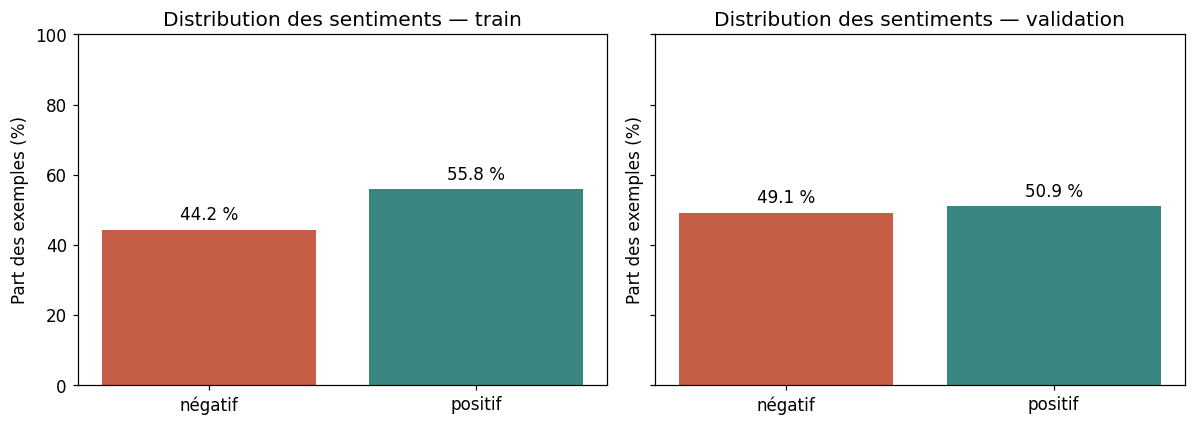

Le sentiment positif représente **55.8 %** du train et **50.9 %** de la validation. Ces proportions donnent le contexte de l'accuracy ; précision, rappel et F1 complètent l'évaluation de la classe positive. Aucun rééquilibrage n'est appliqué.

In [7]:
class_counts = pd.DataFrame({
    name: frame["label"].value_counts().reindex([0, 1], fill_value=0)
    for name, frame in frames.items()
}).T
class_counts.columns = [LABEL_NAMES[0], LABEL_NAMES[1]]
class_percentages = class_counts.div(class_counts.sum(axis=1), axis=0).mul(100)
display(class_counts.rename_axis("split"))
display(class_percentages.round(2).rename_axis("split").add_suffix(" (%)"))

fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, name in zip(axes, frames):
    values = class_percentages.loc[name]
    bars = ax.bar(values.index, values.values, color=["#C65D46", "#378780"])
    ax.bar_label(bars, labels=[f"{value:.1f} %" for value in values], padding=4)
    ax.set(title=f"Distribution des sentiments — {name}", ylim=(0, 100), ylabel="Part des exemples (%)")
fig.tight_layout()
plt.show()

display(Markdown(
    f"Le sentiment positif représente **{class_percentages.loc['train', 'positif']:.1f} %** du train "
    f"et **{class_percentages.loc['validation', 'positif']:.1f} %** de la validation. "
    "Ces proportions donnent le contexte de l'accuracy ; précision, rappel et F1 "
    "complètent l'évaluation de la classe positive. Aucun rééquilibrage n'est appliqué."
))


### Longueur des textes et contrôle des recouvrements

Le nombre de **mots** est estimé par une séparation sur les espaces, ponctuation
comprise ; le nombre de **caractères** inclut les espaces. Il s'agit de mesures
descriptives, distinctes des unités que retient `TfidfVectorizer`.

Le contrôle des doublons ci-dessous recherche les textes identiques après passage
en minuscules et normalisation des espaces. Il ne détecte pas tous les fragments
qui se recouvrent ni les paraphrases. Les splits officiels sont conservés pour la
comparabilité : un éventuel recouvrement provenant du corpus sera signalé, sans
suppression silencieuse d'exemples. Le vocabulaire et les IDF restent appris sur le
train uniquement, indépendamment de ces observations descriptives.


count    mean    std  min    50%    90%     95%  \
split      mesure                                                            
train      n_words       67349.0    9.41   8.07  1.0    7.0   21.0   26.00   
           n_characters  67349.0   53.51  43.41  2.0   39.0  117.0  145.00   
validation n_words         872.0   19.55   8.76  2.0   19.0   31.9   34.45   
           n_characters    872.0  105.84  48.13  6.0  103.0  171.0  186.45   

                            99%    max  
split      mesure                       
train      n_words        35.00   52.0  
           n_characters  194.00  268.0  
validation n_words        42.00   47.0  
           n_characters  222.29  244.0

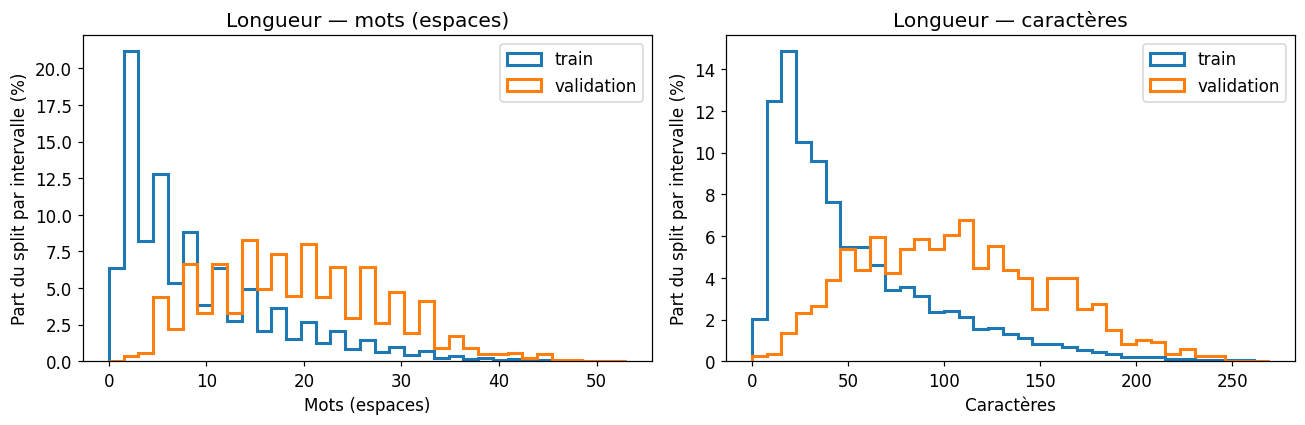

La longueur médiane est de **7 mots** dans le train et **19 mots** dans la validation. La présence de fragments dans le train peut contribuer à cet écart ; ces statistiques ne suffisent pas à en établir toutes les causes. La baseline conserve les textes entiers, sans troncature.

Doublons internes normalisés : {'train': 371, 'validation': 0}
Textes normalisés communs aux splits : 0
Lignes de validation concernées : 0
Aucun texte entier identique détecté avec cette normalisation.


In [8]:
for frame in frames.values():
    frame["n_words"] = frame["sentence"].str.split().str.len()
    frame["n_characters"] = frame["sentence"].str.len()

length_stats = pd.concat({
    name: frame[["n_words", "n_characters"]].describe(percentiles=[0.5, 0.9, 0.95, 0.99]).T
    for name, frame in frames.items()
}, names=["split", "mesure"])
display(length_stats.round(2))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, column, label in zip(axes, ["n_words", "n_characters"], ["Mots (espaces)", "Caractères"]):
    maximum = max(frame[column].max() for frame in frames.values())
    bins = np.linspace(0, maximum + 1, 36)
    for name, frame in frames.items():
        # Pondération en pourcentage pour comparer des splits de tailles différentes.
        ax.hist(frame[column], bins=bins, weights=np.full(len(frame), 100 / len(frame)),
                histtype="step", linewidth=2, label=name)
    ax.set(xlabel=label, ylabel="Part du split par intervalle (%)", title=f"Longueur — {label.lower()}")
    ax.legend()
fig.tight_layout()
plt.show()

train_median = train_df["n_words"].median()
validation_median = validation_df["n_words"].median()
display(Markdown(
    f"La longueur médiane est de **{train_median:.0f} mots** dans le train et "
    f"**{validation_median:.0f} mots** dans la validation. "
    "La présence de fragments dans le train peut contribuer à cet écart ; "
    "ces statistiques ne suffisent pas à en établir toutes les causes. "
    "La baseline conserve les textes entiers, sans troncature."
))

normalized_texts = {
    name: frame["sentence"].str.lower().str.split().str.join(" ")
    for name, frame in frames.items()
}
overlap_texts = set(normalized_texts["train"]) & set(normalized_texts["validation"])
overlap_validation_rows = int(normalized_texts["validation"].isin(overlap_texts).sum())
print("Doublons internes normalisés :", {
    name: int(texts.duplicated().sum()) for name, texts in normalized_texts.items()
})
print(f"Textes normalisés communs aux splits : {len(overlap_texts)}")
print(f"Lignes de validation concernées : {overlap_validation_rows}")
if overlap_texts:
    display(Markdown(
        "**Limite du corpus :** des textes identiques sont présents dans les deux splits. "
        "L'évaluation conserve le protocole officiel ; cette dépendance doit être "
        "mentionnée lors de l'interprétation des scores."
    ))
else:
    print("Aucun texte entier identique détecté avec cette normalisation.")


## 2 — Baseline TF-IDF + régression logistique

Les hyperparamètres suivants sont fixés **sans optimisation sur la validation**.

| Élément | Paramètres et motivation |
| --- | --- |
| TF-IDF | `ngram_range=(1, 2)` : mots et paires de mots pour des indices locaux tels que « not good ». |
| Vocabulaire | `min_df=2`, `max_df=1.0`, `max_features=100000` : écarter les termes présents dans un seul document et limiter la mémoire. |
| Pondération | `sublinear_tf=True`, `use_idf=True`, `smooth_idf=True`, `norm='l2'` : fréquence logarithmique et normalisation par document. |
| Texte | Minuscules ; ni stopwords ni lemmatisation pour conserver notamment les négations. Le motif standard retient les suites d'au moins deux caractères de mot et sépare aux ponctuations. |
| Classifieur | `C=1.0`, pénalité L2, `solver='lbfgs'`, `max_iter=1000`, `tol=1e-4`, `class_weight=None`, `random_state=42`. |

`Pipeline.fit` reçoit exclusivement les 67 349 textes et labels du train.
`Pipeline.predict` transforme la validation avec le vocabulaire et les IDF déjà
appris. Aucune matrice dense n'est créée. Un défaut de convergence interrompt
l'exécution pour éviter d'exporter discrètement une baseline non convergée.

La seed fixe les tirages d'exemples et les composants qui utilisent un générateur
aléatoire. De petites variations numériques restent possibles selon les versions
des bibliothèques et les bibliothèques de calcul du système.


In [9]:
X_train = train_df["sentence"].tolist()
y_train = train_df["label"].to_numpy(dtype=np.int64)
X_validation = validation_df["sentence"].tolist()
y_validation = validation_df["label"].to_numpy(dtype=np.int64)

TFIDF_PARAMS = {
    "ngram_range": (1, 2),
    "min_df": 2,
    "max_df": 1.0,
    "max_features": 100_000,
    "lowercase": True,
    "stop_words": None,
    "sublinear_tf": True,
    "use_idf": True,
    "smooth_idf": True,
    "norm": "l2",
}
LOGREG_PARAMS = {
    "C": 1.0,
    "penalty": "l2",
    "solver": "lbfgs",
    "max_iter": 1000,
    "tol": 1e-4,
    "class_weight": None,
    "random_state": SEED,
}
baseline = Pipeline([
    ("tfidf", TfidfVectorizer(**TFIDF_PARAMS)),
    ("logreg", LogisticRegression(**LOGREG_PARAMS)),
])

training_start = perf_counter()
with warnings.catch_warnings():
    warnings.simplefilter("error", ConvergenceWarning)
    baseline.fit(X_train, y_train)
training_seconds = perf_counter() - training_start
y_pred = baseline.predict(X_validation)

assert len(y_pred) == 872
assert set(np.unique(y_pred)).issubset({0, 1})
print(f"Entraînement CPU : {training_seconds:.2f} s")
print(f"Vocabulaire appris sur train : {len(baseline.named_steps['tfidf'].vocabulary_):,} caractéristiques")
print("Itérations du classifieur :", baseline.named_steps["logreg"].n_iter_.tolist())


Entraînement CPU : 5.56 s
Vocabulaire appris sur train : 74,055 caractéristiques
Itérations du classifieur : [49]


### Mesures sur la validation et analyse des erreurs

L'accuracy est la proportion totale de bonnes prédictions. Les trois métriques
binaires utilisent **1 (positif)** : la précision mesure la part de vrais positifs
parmi les prédictions positives ; le rappel mesure la part de positifs retrouvés ;
F1 est leur moyenne harmonique. Les scores sont exportés entre 0 et 1.
`zero_division=0` fixe explicitement le comportement si un dénominateur est nul.


,accuracy,precision,recall,f1
TF-IDF + régression logistique,0.805,0.7831,0.8536,0.8168


Erreurs : 170 / 872


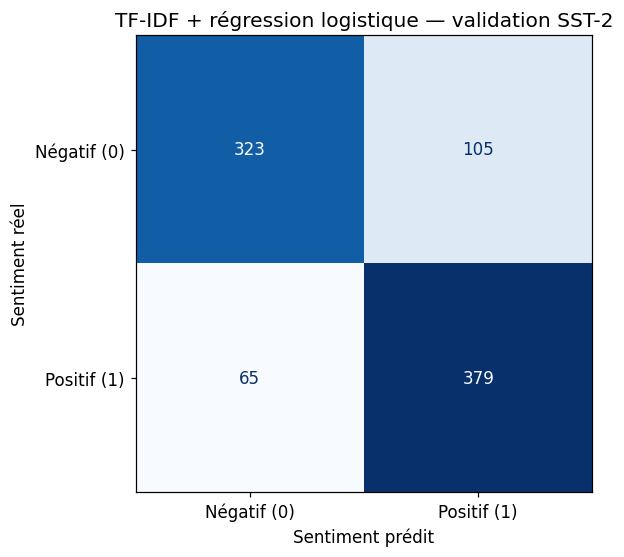

,idx,sentence,true_label,predicted_label,sentiment_reel,sentiment_predit
0,728,"but taken as a stylish and energetic one-shot , the queen of the damned can not be said to suck .",1,0,positif,négatif
1,133,"the tale of tok ( andy lau ) , a sleek sociopath on the trail of o ( takashi sorimachi ) , the most legendary of asian hitmen , is too scattershot to take h...",0,1,négatif,positif
2,631,burns never really harnesses to full effect the energetic cast .,0,1,négatif,positif
3,124,"( lawrence bounces ) all over the stage , dancing , running , sweating , mopping his face and generally displaying the wacky talent that brought him fame in...",1,0,positif,négatif
4,749,a working class `` us vs. them '' opera that leaves no heartstring untugged and no liberal cause unplundered .,1,0,positif,négatif
5,847,"... mafia , rap stars and hood rats butt their ugly heads in a regurgitation of cinematic violence that gives brutal birth to an unlikely , but likable , he...",1,0,positif,négatif
6,856,"in a way , the film feels like a breath of fresh air , but only to those that allow it in .",1,0,positif,négatif
7,248,"a full world has been presented onscreen , not some series of carefully structured plot points building to a pat resolution .",1,0,positif,négatif
8,575,"( director ) o'fallon manages to put some lovely pictures up on the big screen , but his skill at telling a story -- he also contributed to the screenplay -...",0,1,négatif,positif
9,296,its well of thorn and vinegar ( and simple humanity ) has long been plundered by similar works featuring the insight and punch this picture so conspicuously...,0,1,négatif,positif


La baseline atteint **80.50% d'accuracy** et un **F1 positif de 0.8168**, avec **170 erreurs**. La matrice compte **105 faux positifs** et **65 faux négatifs**. Les exemples affichés permettent d'examiner des hypothèses comme la négation, les opinions mixtes ou l'ironie ; ces causes doivent être vérifiées en lisant chaque phrase. Ces résultats constituent le point de départ de la future comparaison.

In [10]:
def compute_binary_metrics(y_true, predictions):
    """Évaluer des labels binaires alignés ; la classe positive est toujours 1."""
    y_true = np.asarray(y_true)
    predictions = np.asarray(predictions)
    if y_true.ndim != 1 or y_true.shape != predictions.shape or y_true.size == 0:
        raise ValueError("Les labels et prédictions doivent être des vecteurs non vides de même taille.")
    if not np.isin(y_true, [0, 1]).all() or not np.isin(predictions, [0, 1]).all():
        raise ValueError("Seuls les labels binaires 0 et 1 sont acceptés.")
    return {
        "accuracy": float(accuracy_score(y_true, predictions)),
        "precision": float(precision_score(y_true, predictions, pos_label=1, zero_division=0)),
        "recall": float(recall_score(y_true, predictions, pos_label=1, zero_division=0)),
        "f1": float(f1_score(y_true, predictions, pos_label=1, zero_division=0)),
    }


metrics = compute_binary_metrics(y_validation, y_pred)
cm = confusion_matrix(y_validation, y_pred, labels=[0, 1])
n_errors = int(np.count_nonzero(y_validation != y_pred))
assert int(cm.sum()) == len(y_validation)
assert int(cm.sum() - np.trace(cm)) == n_errors
display(pd.DataFrame([metrics], index=["TF-IDF + régression logistique"]).round(4))
print(f"Erreurs : {n_errors} / {len(y_validation)}")

fig_cm, ax_cm = plt.subplots(figsize=(6.4, 5.2))
ConfusionMatrixDisplay(cm, display_labels=["Négatif (0)", "Positif (1)"]).plot(
    ax=ax_cm, cmap="Blues", values_format="d", colorbar=False
)
ax_cm.set(title="TF-IDF + régression logistique — validation SST-2",
          xlabel="Sentiment prédit", ylabel="Sentiment réel")
fig_cm.tight_layout()
plt.show()

predictions_df = pd.DataFrame({
    "idx": validation_df["idx"].to_numpy(),
    "sentence": X_validation,
    "true_label": y_validation,
    "predicted_label": y_pred,
})
errors_df = predictions_df.loc[predictions_df["true_label"] != predictions_df["predicted_label"]].copy()
errors_df["sentiment_reel"] = errors_df["true_label"].map(LABEL_NAMES)
errors_df["sentiment_predit"] = errors_df["predicted_label"].map(LABEL_NAMES)
if len(errors_df):
    display(errors_df.sample(n=min(10, len(errors_df)), random_state=SEED).reset_index(drop=True))
else:
    print("Aucune erreur sur la validation.")

display(Markdown(
    f"La baseline atteint **{metrics['accuracy']:.2%} d'accuracy** et un "
    f"**F1 positif de {metrics['f1']:.4f}**, avec **{n_errors} erreurs**. "
    f"La matrice compte **{int(cm[0, 1])} faux positifs** et **{int(cm[1, 0])} faux négatifs**. "
    "Les exemples affichés permettent d'examiner des hypothèses comme la négation, "
    "les opinions mixtes ou l'ironie ; ces causes doivent être vérifiées en lisant "
    "chaque phrase. Ces résultats constituent le point de départ de la future comparaison."
))


### Sauvegarde des résultats réellement calculés

Les fichiers suivants sont créés uniquement après entraînement et évaluation réussis :

- `results/tfidf_metrics.json` : métriques, erreurs, matrice, protocole, hyperparamètres,
  versions et empreintes des données chargées ;
- `results/tfidf_predictions.csv` : les 872 textes de validation dans leur ordre
  officiel, leur identifiant, leur label réel et leur prédiction ;
- `results/tfidf_confusion_matrix.png` : figure lisible avec axes réel/prédit.

Les empreintes des splits facilitent la traçabilité ; elles ne remplacent pas une
révision figée du dépôt de données. Les bornes de dépendances assurent la compatibilité,
pas une reproduction bit à bit entre machines.


In [11]:
metrics_path = RESULTS_DIR / "tfidf_metrics.json"
predictions_path = RESULTS_DIR / "tfidf_predictions.csv"
confusion_path = RESULTS_DIR / "tfidf_confusion_matrix.png"
metrics_payload = {
    **metrics,
    "model": "tfidf_logistic_regression",
    "seed": SEED,
    "positive_label": 1,
    "n_train": len(train_df),
    "n_validation": len(validation_df),
    "n_errors": n_errors,
    "confusion_matrix": cm.tolist(),
    "confusion_matrix_label_order": [0, 1],
    "training_seconds": training_seconds,
    "vocabulary_size": len(baseline.named_steps["tfidf"].vocabulary_),
    "classifier_iterations": baseline.named_steps["logreg"].n_iter_.tolist(),
    "hyperparameters": {"tfidf": TFIDF_PARAMS, "logistic_regression": LOGREG_PARAMS},
    "dataset": {
        "name": "nyu-mll/glue", "configuration": "sst2",
        "fit_split": "train", "evaluation_split": "validation",
        "train_fingerprint": dataset["train"]._fingerprint,
        "validation_fingerprint": dataset["validation"]._fingerprint,
        "normalized_overlap_texts": len(overlap_texts),
        "normalized_overlap_validation_rows": overlap_validation_rows,
    },
    "environment": {"python": platform.python_version(), "platform": platform.system(), "device": "CPU"},
    "library_versions": VERSIONS,
}
metrics_path.write_text(json.dumps(metrics_payload, indent=2, ensure_ascii=False, allow_nan=False) + "\n", encoding="utf-8")
predictions_df.to_csv(predictions_path, index=False, encoding="utf-8")
fig_cm.savefig(confusion_path, dpi=180, bbox_inches="tight", facecolor="white")
plt.close(fig_cm)

# Vérification des exports : schéma, ordre des exemples et cohérence des métriques.
saved_metrics = json.loads(metrics_path.read_text(encoding="utf-8"))
saved_predictions = pd.read_csv(predictions_path, encoding="utf-8", keep_default_na=False)
assert len(saved_predictions) == 872
assert saved_predictions["sentence"].tolist() == X_validation
assert saved_predictions["idx"].tolist() == validation_df["idx"].tolist()
assert saved_predictions["true_label"].tolist() == y_validation.tolist()
assert saved_predictions["predicted_label"].tolist() == y_pred.tolist()
recomputed_metrics = compute_binary_metrics(saved_predictions["true_label"], saved_predictions["predicted_label"])
for name, value in recomputed_metrics.items():
    assert np.isclose(value, saved_metrics[name]), name
assert confusion_path.read_bytes().startswith(b"\x89PNG\r\n\x1a\n")
for path in (metrics_path, predictions_path, confusion_path):
    print(f"Créé et vérifié : {path.name} ({path.stat().st_size:,} octets)")


Créé et vérifié : tfidf_metrics.json (1,635 octets)
Créé et vérifié : tfidf_predictions.csv (101,040 octets)
Créé et vérifié : tfidf_confusion_matrix.png (48,463 octets)


### Récupération dans Colab et arrêt de la phase 1

La cellule suivante crée une archive des **trois résultats réels**. Dans Colab,
elle lance son téléchargement ; si le navigateur le bloque, récupérer les fichiers
dans le panneau **Fichiers → results**. Télécharger également le notebook exécuté
via **Fichier → Télécharger → Télécharger le fichier .ipynb** pour conserver les sorties.

**À faire valider :** notebook exécuté, JSON des métriques, CSV des prédictions et
PNG de la matrice. Aucun score de BERT n'a été calculé. BERT et le reporting
comparatif sont réservés aux phases suivantes.

**Fin de la phase 1.** Attendre la validation explicite :
« Phase 1 validée, passe à la phase 2. »


In [12]:
archive_path = RESULTS_DIR / "phase1_results.zip"
with ZipFile(archive_path, "w") as archive:
    for path in (metrics_path, predictions_path, confusion_path):
        archive.write(path, arcname=path.name)
print(f"Archive des résultats : {archive_path}")
if IN_COLAB:
    from google.colab import files
    files.download(str(archive_path))


Archive des résultats : /content/results/phase1_results.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### Références

- Support local : `NLP_Course_Module7_Transformer_BERT (1).pptx`, dans le ZIP fourni,
  consulté en lecture seule ; étapes « Explore » et « Baseline ».
- [Fiche officielle GLUE / SST-2](https://huggingface.co/datasets/nyu-mll/glue).
- [TF-IDF dans scikit-learn](https://scikit-learn.org/1.7/modules/generated/sklearn.feature_extraction.text.TfidfVectorizer.html).
- [Régression logistique dans scikit-learn](https://scikit-learn.org/1.7/modules/generated/sklearn.linear_model.LogisticRegression.html).


## 3 — BERT : tokenisation et validation technique (phase 2)

La phase 1 a été validée et publiée dans le commit
[`ecb4c82`](https://github.com/gueri-jpg/nlp-bert-vs-tfidf-sst2/commit/ecb4c82e3a36fd1c3d3d05b2efaad01e996feb5a).
Les sections 0 à 2, leurs sorties et les trois résultats TF-IDF sont conservés.
Leurs mentions « phase 1 uniquement » décrivent ce premier jalon historique.

**Pour cette phase, démarrer une session neuve et exécuter uniquement les cellules
à partir de cette section 3, dans l'ordre.** Elle possède ses propres imports et
charge SST-2 sans dépendre des variables de la baseline. Ne pas utiliser « Tout
exécuter » sur le notebook entier : les anciennes cellules réentraîneraient la
baseline et réécriraient ses exports. Aucun fichier TF-IDF n'est écrit en section 3.

Le modèle imposé est **`bert-base-uncased`**. Cette phase prépare les données et
effectue, si la mémoire le permet, **deux étapes d'optimisation au maximum** sur
16 exemples de train, puis prédit sur 8 exemples de validation. Ce smoke test est
un contrôle technique, sans valeur de comparaison avec la baseline.
L'entraînement complet et toute comparaison statistique restent réservés à la phase 3.


### 3.0 — Installation, versions, API et ressources

La cellule d'installation reprend les bornes de `requirements.txt`, y compris les
dépendances de base, pour fonctionner depuis une session Colab vide. Elle conserve
une installation PyTorch compatible déjà présente, notamment sa variante CUDA.
Transformers est borné à la branche 4.57 ; les paramètres de `Trainer` et
`TrainingArguments` sont également contrôlés par introspection à l'exécution.

Si une bibliothèque déjà importée est remplacée (en particulier Hugging Face Hub),
redémarrer la session avant de continuer. Sous Colab, choisir un GPU T4 si disponible.
Sans GPU, le code utilise le CPU ; le téléchargement des poids et le smoke test
sont différés si la RAM libre est insuffisante. Le contrôle mémoire est une
estimation prudente, pas une garantie contre un dépassement.


In [13]:
%pip install -q "numpy>=1.26,<3" "pandas>=2.2,<3" "scikit-learn>=1.5,<1.8" "matplotlib>=3.9,<3.11" "datasets>=3,<5" "ipython>=8,<10" "torch>=2.6,<3" "transformers>=4.57,<5" "accelerate>=1.6,<2" "safetensors>=0.4.3,<1" "psutil>=5.9,<8"


ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio-client 2.7.2 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio 6.31.0 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
diffusers 0.42.1 requires huggingface-hub<3.0,>=1.32.0, but you have huggingface-hub 0.36.2 which is incompatible.


In [14]:
import gc
import hashlib
import importlib.metadata
import importlib.util
import inspect
import json
import os
import sys
from pathlib import Path
import platform
from datetime import datetime, timezone
import warnings
import importlib

PHASE2_ROOT = Path.cwd().resolve()
if PHASE2_ROOT.name == "notebooks":
    PHASE2_ROOT = PHASE2_ROOT.parent
PHASE2_RESULTS = PHASE2_ROOT / "results" / "phase2"
PHASE2_RESULTS.mkdir(parents=True, exist_ok=True)
PHASE2_CACHE = PHASE2_ROOT / ".cache"
os.environ.setdefault("HF_HOME", str(PHASE2_CACHE / "huggingface"))
os.environ.setdefault("MPLCONFIGDIR", str(PHASE2_CACHE / "matplotlib"))
os.environ.setdefault("USE_TF", "0")

# Force le rechargement complet de huggingface_hub pour éviter les imports cassés
for key in list(sys.modules.keys()):
    if key == "huggingface_hub" or key.startswith("huggingface_hub."):
        sys.modules.pop(key, None)

import huggingface_hub
importlib.reload(huggingface_hub)

if huggingface_hub.__version__ != importlib.metadata.version("huggingface-hub"):
    warnings.warn(f"Hugging Face Hub version mismatch (memory: {huggingface_hub.__version__} vs metadata: {importlib.metadata.version('huggingface-hub')}). Attempting to proceed.")

import accelerate
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import psutil
import torch
import transformers
from datasets import DatasetDict, load_dataset
from IPython.display import Markdown, display
from sklearn.metrics import accuracy_score, f1_score
from transformers import (
    AutoTokenizer, AutoModelForSequenceClassification, DataCollatorWithPadding,
    Trainer, TrainerCallback, TrainingArguments, set_seed,
)

BERT_MODEL_NAME = "bert-base-uncased"
BERT_SEED = 42
set_seed(BERT_SEED)
HAS_CUDA = torch.cuda.is_available()
BERT_DEVICE = torch.device("cuda" if HAS_CUDA else "cpu")
torch.set_num_threads(min(4, torch.get_num_threads()))
PHASE2_VERSIONS = {
    name: importlib.metadata.version(name)
    for name in ("torch", "transformers", "accelerate", "datasets", "tokenizers", "huggingface-hub", "safetensors", "numpy", "psutil")
}
training_api = inspect.signature(TrainingArguments.__init__).parameters
trainer_api = inspect.signature(Trainer.__init__).parameters
assert {"eval_strategy", "use_cpu", "max_steps", "save_strategy"}.issubset(training_api)
assert {"processing_class", "compute_metrics", "data_collator"}.issubset(trainer_api)
assert callable(getattr(TrainerCallback, "on_pre_optimizer_step", None))


def bert_memory_snapshot():
    snapshot = {
        "ram_available_gib": psutil.virtual_memory().available / 2**30,
        "process_rss_gib": psutil.Process().memory_info().rss / 2**30,
    }
    if HAS_CUDA:
        free, total = torch.cuda.mem_get_info()
        snapshot.update({
            "gpu_free_gib": free / 2**30, "gpu_total_gib": total / 2**30,
            "gpu_allocated_gib": torch.cuda.memory_allocated() / 2**30,
            "gpu_reserved_gib": torch.cuda.memory_reserved() / 2**30,
            "gpu_peak_allocated_gib": torch.cuda.max_memory_allocated() / 2**30,
        })
    return snapshot


BASELINE_FILES = [PHASE2_ROOT / "results" / name for name in
                  ("tfidf_metrics.json", "tfidf_predictions.csv", "tfidf_confusion_matrix.png")]
baseline_hashes_before = {p.name: hashlib.sha256(p.read_bytes()).hexdigest()
                          for p in BASELINE_FILES if p.exists()}
phase2_memory_initial = bert_memory_snapshot()
print("Python :", platform.python_version(), "| calcul :", BERT_DEVICE)
display(pd.Series(PHASE2_VERSIONS, name="version").to_frame())
print("API présentes : eval_strategy, use_cpu, processing_class, on_pre_optimizer_step.")
if HAS_CUDA:
    print("GPU :", torch.cuda.get_device_name(0), "| CUDA PyTorch :", torch.version.cuda)
else:
    print("Aucun GPU CUDA : tokenisation sur CPU ; smoke test CPU seulement si la RAM le permet.")
print("Mémoire initiale :", phase2_memory_initial)

Python : 3.13.16 | calcul : cuda


,version
torch,2.14.1+cu130
transformers,4.57.6
accelerate,1.15.0
datasets,4.8.5
tokenizers,0.22.2
huggingface-hub,0.36.2
safetensors,0.8.0
numpy,2.4.6
psutil,7.2.2


API présentes : eval_strategy, use_cpu, processing_class, on_pre_optimizer_step.
GPU : Tesla T4 | CUDA PyTorch : 13.0
Mémoire initiale : {'ram_available_gib': 9.336013793945312, 'process_rss_gib': 1.242828369140625, 'gpu_free_gib': 14.46075439453125, 'gpu_total_gib': 14.56317138671875, 'gpu_allocated_gib': 0.0, 'gpu_reserved_gib': 0.0, 'gpu_peak_allocated_gib': 0.0}


### 3.1 — WordPiece, identifiants, masques, padding et troncature

Le tokenizer **uncased** met en minuscules et segmente le texte en sous-mots
WordPiece. `##` indique une continuation de mot. Cette segmentation utilise un
vocabulaire préentraîné fixe : **la tokenisation elle-même n'est pas contextuelle**.
Ce sont les représentations calculées ensuite par l'encodeur BERT qui dépendent
du contexte, grâce à l'attention bidirectionnelle.

`[CLS]` ouvre la séquence et sa représentation finale alimente la classification ;
`[SEP]` marque ici sa fin ; `[PAD]` complète les séquences plus courtes d'un lot.
`input_ids` contient les indices du vocabulaire et `attention_mask` vaut 1 sur les
positions réelles, 0 sur le padding. Pour ces textes à une seule séquence,
`token_type_ids` vaut 0. La troncature réduit les textes trop longs tout en gardant
les tokens spéciaux. Dans la préparation réelle, le padding sera dynamique.

TF-IDF construit un vecteur creux de fréquences pondérées et de bigrammes locaux,
avec vocabulaire/IDF appris sur le train. BERT reçoit une suite ordonnée d'indices,
puis produit des vecteurs contextuels ; aucune IDF n'est apprise par son tokenizer.


In [15]:
bert_tokenizer = AutoTokenizer.from_pretrained(
    BERT_MODEL_NAME, use_fast=True, cache_dir=str(PHASE2_CACHE / "bert")
)
assert bert_tokenizer.is_fast
assert [bert_tokenizer.cls_token, bert_tokenizer.sep_token, bert_tokenizer.pad_token] == ["[CLS]", "[SEP]", "[PAD]"]
original_sentence = "The cinematography was surprisingly beautiful, but the ending was disappointing and the character development felt unnecessarily predictable."
wordpieces = bert_tokenizer.tokenize(original_sentence)
print("Phrase originale :", original_sentence)
print("WordPiece sans tokens spéciaux :", wordpieces)
print("Tokens spéciaux :", {name: getattr(bert_tokenizer, name) for name in
      ("cls_token_id", "sep_token_id", "pad_token_id")})

demo_texts = ["A good film.", original_sentence]
demo_encoded = bert_tokenizer(demo_texts, padding="max_length", truncation=True, max_length=16)
for text, ids, mask, segments in zip(demo_texts, demo_encoded["input_ids"],
                                     demo_encoded["attention_mask"], demo_encoded["token_type_ids"]):
    display(Markdown(f"**Texte :** {text}"))
    display(pd.DataFrame({
        "token": bert_tokenizer.convert_ids_to_tokens(ids),
        "input_ids": ids, "attention_mask": mask, "token_type_ids": segments,
    }).T)
    assert ids[0] == bert_tokenizer.cls_token_id
    assert ids[sum(mask) - 1] == bert_tokenizer.sep_token_id
    assert all(token_id == bert_tokenizer.pad_token_id for token_id, active in zip(ids, mask) if active == 0)
    print("Longueur initiale avec tokens spéciaux :", len(bert_tokenizer(text)["input_ids"]),
          "| longueur utile après troncature :", sum(mask), "| longueur complétée :", len(ids))
assert 0 in demo_encoded["attention_mask"][0]
assert len(bert_tokenizer(original_sentence)["input_ids"]) > 16


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

Phrase originale : The cinematography was surprisingly beautiful, but the ending was disappointing and the character development felt unnecessarily predictable.
WordPiece sans tokens spéciaux : ['the', 'cinematography', 'was', 'surprisingly', 'beautiful', ',', 'but', 'the', 'ending', 'was', 'disappointing', 'and', 'the', 'character', 'development', 'felt', 'un', '##ne', '##ces', '##sari', '##ly', 'predictable', '.']
Tokens spéciaux : {'cls_token_id': 101, 'sep_token_id': 102, 'pad_token_id': 0}


... (2 outputs left out)

Longueur initiale avec tokens spéciaux : 6 | longueur utile après troncature : 6 | longueur complétée : 16


**Texte :** The cinematography was surprisingly beautiful, but the ending was disappointing and the character development felt unnecessarily predictable.

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15
token,[CLS],the,cinematography,was,surprisingly,beautiful,",",but,the,ending,was,disappointing,and,the,character,[SEP]
input_ids,101,1996,16434,2001,10889,3376,1010,2021,1996,4566,2001,15640,1998,1996,2839,102
attention_mask,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1
token_type_ids,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0


Longueur initiale avec tokens spéciaux : 25 | longueur utile après troncature : 16 | longueur complétée : 16


### 3.2 — Choisir `max_length` avec le train uniquement

Nous comptons les unités WordPiece **y compris `[CLS]` et `[SEP]`**, sans padding
ni troncature, sur tous les textes du train. Le plus petit seuil parmi
`64, 128, 256, 512` couvrant au moins **99 % du train** est retenu ; cette règle est
fixée avant toute mesure sur la validation. Les textes excédentaires seront
tronqués. Le plafond ne doit pas dépasser la capacité du modèle.


Using the latest cached version of the dataset since nyu-mll/glue couldn't be found on the Hugging Face Hub
Found the latest cached dataset configuration 'sst2' at /content/.cache/huggingface/datasets/nyu-mll___glue/sst2/0.0.0/bcdcba79d07bc864c1c254ccfcedcce55bcc9a8c (last modified on Wed Nov 25 19:14:44 2026).


Longueurs WordPiece sur train uniquement:   0%|          | 0/67349 [00:00<?, ? examples/s]

,WordPiece avec tokens spéciaux
count,67349.00
mean,13.32
std,9.55
min,3.00
50%,10.00
90%,27.00
95%,33.00
99%,44.00
max,66.00


,max_length,couverture_train_pct,textes_tronques
0,64,99.994061,4
1,128,100.000000,0
2,256,100.000000,0
3,512,100.000000,0


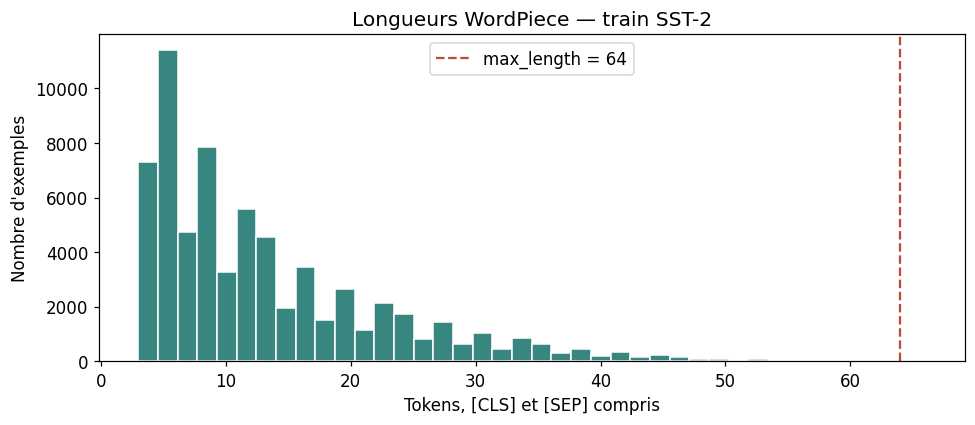

**Choix : `max_length=64`**, couvrant **99.99 %** du train sans troncature. Ce compromis limite la mémoire et le coût de l'attention. Il pourra tronquer des phrases de validation plus longues ; aucun score de validation n'a servi à le choisir.

In [16]:
bert_source = load_dataset("nyu-mll/glue", "sst2")
bert_raw = DatasetDict({name: bert_source[name] for name in ("train", "validation")})
assert len(bert_raw["train"]) == 67_349 and len(bert_raw["validation"]) == 872


def count_wordpieces(batch):
    encoded = bert_tokenizer(batch["sentence"], truncation=False, padding=False, return_length=True)
    return {"wordpiece_length": encoded["length"]}


wordpiece_lengths = bert_raw["train"].map(
    count_wordpieces, batched=True, batch_size=512,
    remove_columns=bert_raw["train"].column_names,
    desc="Longueurs WordPiece sur train uniquement",
)
train_wordpiece_lengths = np.asarray(wordpiece_lengths["wordpiece_length"])
display(pd.Series(train_wordpiece_lengths, name="WordPiece avec tokens spéciaux")
        .describe(percentiles=[0.5, 0.9, 0.95, 0.99]).to_frame().round(2))
length_coverage = pd.DataFrame([
    {"max_length": length, "couverture_train_pct": float(np.mean(train_wordpiece_lengths <= length) * 100),
     "textes_tronques": int(np.sum(train_wordpiece_lengths > length))}
    for length in (64, 128, 256, 512)
])
display(length_coverage)
MAX_LENGTH = next(int(row.max_length) for row in length_coverage.itertuples() if row.couverture_train_pct >= 99)
assert MAX_LENGTH <= bert_tokenizer.model_max_length

fig_wp, ax_wp = plt.subplots(figsize=(9, 4))
ax_wp.hist(train_wordpiece_lengths, bins=40, color="#378780", edgecolor="white")
ax_wp.axvline(MAX_LENGTH, color="#B94E38", linestyle="--", label=f"max_length = {MAX_LENGTH}")
ax_wp.set(title="Longueurs WordPiece — train SST-2", xlabel="Tokens, [CLS] et [SEP] compris", ylabel="Nombre d'exemples")
ax_wp.legend()
fig_wp.tight_layout()
plt.show()
chosen_coverage = float(np.mean(train_wordpiece_lengths <= MAX_LENGTH) * 100)
display(Markdown(
    f"**Choix : `max_length={MAX_LENGTH}`**, couvrant **{chosen_coverage:.2f} %** du train sans troncature. "
    "Ce compromis limite la mémoire et le coût de l'attention. Il pourra tronquer "
    "des phrases de validation plus longues ; aucun score de validation n'a servi à le choisir."
))


### 3.3 — Données alignées et padding dynamique

`bert_tokenized` conserve `idx` et `sentence` pour l'analyse et les futurs exports.
Le champ `label` devient `labels` sans changer ses valeurs. Une vue séparée
`bert_model_inputs` ne contient que les champs acceptés par le modèle.
`DataCollatorWithPadding` complète chaque lot à sa séquence la plus longue,
au lieu de compléter tout le corpus à `max_length`. Les deux vues gardent
strictement l'ordre et le nombre d'exemples du split officiel.


In [17]:
def tokenize_bert_batch(batch):
    """Tokeniser sans padding, conserver la troncature fixée à partir du train."""
    return bert_tokenizer(batch["sentence"], truncation=True, max_length=MAX_LENGTH, padding=False)


bert_tokenized = bert_raw.map(tokenize_bert_batch, batched=True, batch_size=512,
                              desc="Tokenisation BERT des splits officiels")
bert_tokenized = bert_tokenized.rename_column("label", "labels")
BERT_INPUT_COLUMNS = ["input_ids", "attention_mask", "token_type_ids", "labels"]
bert_model_inputs = DatasetDict({
    name: split.remove_columns([column for column in split.column_names if column not in BERT_INPUT_COLUMNS])
    for name, split in bert_tokenized.items()
})
bert_collator = DataCollatorWithPadding(tokenizer=bert_tokenizer, padding=True, return_tensors="pt")

for name in ("train", "validation"):
    aligned = bert_tokenized[name]
    assert len(aligned) == len(bert_raw[name])
    assert list(aligned["idx"]) == list(bert_raw[name]["idx"])
    assert list(aligned["sentence"]) == list(bert_raw[name]["sentence"])
    assert list(aligned["labels"]) == list(bert_raw[name]["label"])
    assert set(aligned["labels"]) == {0, 1}
    assert len(set(aligned["idx"])) == len(aligned)
    for row in bert_model_inputs[name]:
        length = len(row["input_ids"])
        assert 2 <= length <= MAX_LENGTH
        assert length == len(row["attention_mask"]) == len(row["token_type_ids"])
        assert row["attention_mask"] == [1] * length
        assert row["token_type_ids"] == [0] * length
        assert row["input_ids"][0] == bert_tokenizer.cls_token_id
        assert row["input_ids"][-1] == bert_tokenizer.sep_token_id

probe_features = [bert_model_inputs["train"][i] for i in range(4)]
bert_probe_batch = bert_collator(probe_features)
batch_shape = bert_probe_batch["input_ids"].shape
assert tuple(batch_shape) == (4, max(len(row["input_ids"]) for row in probe_features))
assert bert_probe_batch["attention_mask"].shape == batch_shape
assert bert_probe_batch["token_type_ids"].shape == batch_shape
assert bert_probe_batch["labels"].shape == (4,)
assert bert_probe_batch["labels"].dtype == torch.long
for index, feature in enumerate(probe_features):
    length = len(feature["input_ids"])
    assert bert_probe_batch["attention_mask"][index].sum().item() == length
    assert torch.all(bert_probe_batch["attention_mask"][index, length:] == 0)
    assert torch.all(bert_probe_batch["input_ids"][index, length:] == bert_tokenizer.pad_token_id)
print("Alignement idx/textes/labels et dimensions de tous les exemples : OK")
print("Lot dynamique :", {name: tuple(value.shape) for name, value in bert_probe_batch.items()})


Tokenisation BERT des splits officiels:   0%|          | 0/67349 [00:00<?, ? examples/s]

Tokenisation BERT des splits officiels:   0%|          | 0/872 [00:00<?, ? examples/s]

Alignement idx/textes/labels et dimensions de tous les exemples : OK
Lot dynamique : {'labels': (4,), 'input_ids': (4, 15), 'token_type_ids': (4, 15), 'attention_mask': (4, 15)}


### 3.4 — Encodeur préentraîné et tête de classification

`bert-base-uncased` possède 12 couches d'encodeur, des représentations de dimension
768 et 12 têtes d'attention par couche. Son préentraînement inclut le **MLM** :
reconstruire des mots masqués à partir des autres tokens. BERT a aussi utilisé
une tâche de prédiction de phrase suivante (NSP). Ce préentraînement ne lui fournit
pas directement un classifieur SST-2.

`AutoModelForSequenceClassification(..., num_labels=2)` réutilise l'encodeur et
ajoute une tête binaire. Pour BERT, la représentation finale de `[CLS]` passe par
le pooler, puis un dropout et la couche linéaire vers deux logits. Avec `labels`,
le modèle calcule une loss d'entropie croisée. Le fine-tuning supervisé modifiera
la tête **et l'encodeur**, à partir des labels du train.

L'avertissement de poids nouvellement initialisés pour `classifier.weight` et
`classifier.bias` est donc normal : cette tête n'a pas été entraînée pour SST-2.
Il faut vérifier les noms concernés ; un avertissement concernant de nombreuses
couches de l'encodeur ne doit pas être ignoré. Aucun score avant/après quelques
étapes ne constitue une performance finale.

Les poids sont téléchargés uniquement dans `.cache/bert/`, ignoré par Git. Avant
ce téléchargement, nous demandons au moins **3 Gio de RAM libre sur CPU**, ou
**2 Gio de RAM et 3 Gio de VRAM libres sur CUDA**. En cas d'insuffisance, le
notebook conserve les contrôles de tokenisation et indique les tests différés.


In [18]:
phase2_checks = {
    "api_signatures": "passed", "wordpiece_and_special_tokens": "passed",
    "train_length_distribution": "passed", "tokenized_alignment_and_masks": "passed",
    "dynamic_padding": "passed", "model_loading": "not_executed",
    "forward_and_loss": "not_executed", "trainer_backward_and_updates": "not_executed",
    "smoke_prediction_export": "not_executed",
}
smoke_status = "not_started"
smoke_reason = None
bert_model = None
smoke_trainer = None
smoke_metrics = None
smoke_predictions_path = None
gradient_check = None
phase2_memory_before_model = bert_memory_snapshot()
enough_memory = (
    phase2_memory_before_model["ram_available_gib"] >= (2.0 if HAS_CUDA else 3.0)
    and (not HAS_CUDA or phase2_memory_before_model["gpu_free_gib"] >= 3.0)
)

if enough_memory:
    try:
        set_seed(BERT_SEED)
        bert_model = AutoModelForSequenceClassification.from_pretrained(
            BERT_MODEL_NAME, num_labels=2,
            id2label={0: "negative", 1: "positive"}, label2id={"negative": 0, "positive": 1},
            cache_dir=str(PHASE2_CACHE / "bert"), use_safetensors=True,
        ).to(BERT_DEVICE)
        assert bert_model.config.model_type == "bert"
        assert bert_model.config.num_labels == 2
        assert bert_model.config.max_position_embeddings >= MAX_LENGTH
        assert bert_model.classifier.out_features == 2
        assert all(parameter.requires_grad for parameter in bert_model.parameters())
        phase2_checks["model_loading"] = "passed"
        print("Modèle chargé :", type(bert_model).__name__)
        print("Paramètres entraînables :", sum(p.numel() for p in bert_model.parameters() if p.requires_grad))
    except (RuntimeError, MemoryError) as exc:
        if not isinstance(exc, (torch.OutOfMemoryError, MemoryError)) and not any(
            text in str(exc).lower() for text in ("out of memory", "not enough memory", "can't allocate memory")
        ):
            raise
        bert_model = None
        gc.collect()
        if HAS_CUDA:
            torch.cuda.empty_cache()
        smoke_status = "deferred_memory"
        smoke_reason = f"Mémoire insuffisante pendant le chargement : {type(exc).__name__}"
else:
    smoke_status = "deferred_memory"
    smoke_reason = "RAM/VRAM libre sous le seuil de précaution ; poids non téléchargés et smoke test différé."

print("Mémoire avant chargement :", phase2_memory_before_model)
if bert_model is None:
    print("TESTS MODÈLE NON EXÉCUTÉS :", smoke_reason)
    print("Sur Colab : choisir un GPU, redémarrer la session si nécessaire, puis reprendre en section 3.")


model.safetensors:   0%|          | 0.00/440M [00:00<?, ?B/s]

Some weights of BertForSequenceClassification were not initialized from the model checkpoint at bert-base-uncased and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Modèle chargé : BertForSequenceClassification
Paramètres entraînables : 109483778
Mémoire avant chargement : {'ram_available_gib': 10.748565673828125, 'process_rss_gib': 1.3310317993164062, 'gpu_free_gib': 14.46075439453125, 'gpu_total_gib': 14.56317138671875, 'gpu_allocated_gib': 0.0, 'gpu_reserved_gib': 0.0, 'gpu_peak_allocated_gib': 0.0}


### 3.5 — Trainer : configuration prévue et smoke test borné

Le dictionnaire `PHASE3_PLAN` décrit uniquement la future expérience : **2 époques,
learning rate `2e-5`, seed 42**, batch 16 sur GPU (2 sur CPU à adapter), accuracy et
F1 de la classe positive 1. **Il ne lance aucun entraînement.** La taille effective
du batch pourra être ajustée en phase 3 selon la mémoire disponible.

Le seul `Trainer` exécuté ici reçoit **16 exemples de train** et **8 exemples de
validation**, choisis avec la seed 42 et sans mélange des splits. `max_steps=2`
limite le nombre de mises à jour, avec batch 2 sur GPU ou 1 sur CPU. Le smoke test
utilise du float32 et un learning rate constant pour faciliter les contrôles.
Un callback vérifie des gradients finis et non nuls dans la tête et l'encodeur
avant l'optimiseur ; les poids sont comparés avant/après les deux mises à jour.

Aucun checkpoint n'est sauvegardé, aucun envoi vers le Hub ni service de suivi
externe n'est activé. Les éventuels scores sont marqués **smoke uniquement**.
Après ce test, le modèle est modifié : **la phase 3 devra recharger le modèle
préentraîné avec la seed 42**, sans repartir de ces poids techniques.


In [19]:
PHASE3_PLAN = {
    "model": BERT_MODEL_NAME, "num_train_epochs": 2, "learning_rate": 2e-5,
    "seed": BERT_SEED, "per_device_train_batch_size": 16 if HAS_CUDA else 2,
    "per_device_eval_batch_size": 32 if HAS_CUDA else 2,
    "max_length": MAX_LENGTH, "metrics": ["accuracy", "f1_positive"],
    "positive_label": 1, "device": str(BERT_DEVICE),
    "status": "planned_only_requires_phase3_approval",
}
SMOKE_TRAIN_SIZE = 16
SMOKE_VALIDATION_SIZE = 8
SMOKE_MAX_STEPS = 2
smoke_train_indices = bert_raw["train"].shuffle(seed=BERT_SEED).select(range(SMOKE_TRAIN_SIZE))["idx"]
smoke_validation_indices = bert_raw["validation"].shuffle(seed=BERT_SEED).select(range(SMOKE_VALIDATION_SIZE))["idx"]

# Les indices idx de SST-2 correspondent ici aux positions, ce qui est vérifié.
assert list(bert_raw["train"]["idx"]) == list(range(len(bert_raw["train"])))
assert list(bert_raw["validation"]["idx"]) == list(range(len(bert_raw["validation"])))
smoke_train_inputs = bert_model_inputs["train"].select(smoke_train_indices)
smoke_validation_inputs = bert_model_inputs["validation"].select(smoke_validation_indices)
smoke_validation_source = bert_raw["validation"].select(smoke_validation_indices)
assert len(smoke_train_inputs) == 16 and len(smoke_validation_inputs) == 8


def compute_bert_metrics(evaluation):
    logits = evaluation.predictions[0] if isinstance(evaluation.predictions, tuple) else evaluation.predictions
    predictions = np.argmax(logits, axis=-1)
    return {
        "accuracy": float(accuracy_score(evaluation.label_ids, predictions)),
        "f1_positive": float(f1_score(evaluation.label_ids, predictions, pos_label=1, zero_division=0)),
    }


class BertGradientCheck(TrainerCallback):
    """Vérifier la rétropropagation avant que l'optimiseur n'efface les gradients."""
    def __init__(self):
        self.checked_steps = 0
        self.completed_steps = 0

    def on_pre_optimizer_step(self, args, state, control, model=None, **kwargs):
        for parameter in (model.classifier.weight, model.bert.encoder.layer[0].attention.output.dense.bias):
            gradient = parameter.grad
            if gradient is None or not torch.isfinite(gradient).all() or not torch.any(gradient != 0):
                raise RuntimeError("Gradient absent, non fini ou nul dans la tête ou l'encodeur.")
        self.checked_steps += 1

    def on_step_end(self, args, state, control, **kwargs):
        self.completed_steps = state.global_step


smoke_args = TrainingArguments(
    output_dir=str(PHASE2_CACHE / "bert-smoke"), max_steps=SMOKE_MAX_STEPS,
    per_device_train_batch_size=2 if HAS_CUDA else 1,
    per_device_eval_batch_size=2 if HAS_CUDA else 1,
    gradient_accumulation_steps=1, learning_rate=2e-5, lr_scheduler_type="constant",
    seed=BERT_SEED, data_seed=BERT_SEED, use_cpu=not HAS_CUDA,
    fp16=False, bf16=False, optim="adamw_torch",
    eval_strategy="no", save_strategy="no", logging_strategy="steps", logging_steps=1,
    report_to="none", push_to_hub=False, disable_tqdm=True,
    dataloader_num_workers=0, dataloader_pin_memory=HAS_CUDA,
)
assert smoke_args.max_steps == 2 and smoke_args.gradient_accumulation_steps == 1
print("Plan phase 3, sans exécution :", PHASE3_PLAN)
print("Smoke test :", len(smoke_train_inputs), "exemples train,", len(smoke_validation_inputs),
      "exemples validation,", smoke_args.max_steps, "étapes maximum.")


Plan phase 3, sans exécution : {'model': 'bert-base-uncased', 'num_train_epochs': 2, 'learning_rate': 2e-05, 'seed': 42, 'per_device_train_batch_size': 16, 'per_device_eval_batch_size': 32, 'max_length': 64, 'metrics': ['accuracy', 'f1_positive'], 'positive_label': 1, 'device': 'cuda', 'status': 'planned_only_requires_phase3_approval'}
Smoke test : 16 exemples train, 8 exemples validation, 2 étapes maximum.


### Prédictions individuelles et futures comparaisons appariées

L'export conserve **`split`, `idx`, `sentence`, `true_label`, `predicted_label`**,
ainsi que les deux logits et la probabilité positive. `run_kind="smoke"` identifie
explicitement le test technique. Les huit lignes sont exportées sous
`results/phase2/bert_smoke_predictions.csv` seulement après un test réussi.

Pour la future expérience complète, conserver les **872 prédictions** dans
`results/bert_predictions.csv`, avec le même schéma et l'indication d'une expérience
complète. L'appariement avec TF-IDF devra se faire par `(split, idx)` — les `idx`
sont propres à chaque split — puis vérifier l'égalité des textes et labels.
Cela permettra de compter les désaccords et, si retenu, de construire la table de
McNemar sur les erreurs appariées. Aucun test statistique ni comparaison de scores
n'est réalisé dans cette phase ; les huit prédictions techniques n'y conviennent pas.


In [20]:
def export_bert_predictions(prediction_output, source_split, destination, *, run_kind):
    """Exporter dans l'ordre de source_split, sans perdre l'alignement individuel."""
    logits = prediction_output.predictions
    if isinstance(logits, tuple):
        logits = logits[0]
    logits = np.asarray(logits)
    labels = np.asarray(source_split["label"], dtype=np.int64)
    if labels.ndim != 1 or not np.isin(labels, [0, 1]).all():
        raise ValueError("Les labels source doivent être binaires.")
    if logits.shape != (len(source_split), 2) or not np.isfinite(logits).all():
        raise ValueError("Logits non finis ou dimensions incompatibles avec les exemples.")
    if not np.array_equal(prediction_output.label_ids, labels):
        raise ValueError("Les labels de Trainer ne sont pas alignés avec le split source.")
    if not run_kind or len(set(source_split["idx"])) != len(source_split):
        raise ValueError("Type d'expérience requis et idx uniques dans le split nécessaires.")
    shifted = logits - logits.max(axis=1, keepdims=True)
    probabilities = np.exp(shifted) / np.exp(shifted).sum(axis=1, keepdims=True)
    table = pd.DataFrame({
        "split": "validation", "idx": list(source_split["idx"]),
        "sentence": list(source_split["sentence"]), "true_label": labels,
        "predicted_label": logits.argmax(axis=1), "probability_positive": probabilities[:, 1],
        "logit_0": logits[:, 0], "logit_1": logits[:, 1], "run_kind": run_kind,
        "model_name": BERT_MODEL_NAME, "max_length": MAX_LENGTH, "seed": BERT_SEED,
    })
    destination = Path(destination)
    destination.parent.mkdir(parents=True, exist_ok=True)
    table.to_csv(destination, index=False, encoding="utf-8")
    reloaded = pd.read_csv(destination, keep_default_na=False)
    assert reloaded["idx"].tolist() == list(source_split["idx"])
    assert reloaded["sentence"].tolist() == list(source_split["sentence"])
    assert reloaded["true_label"].tolist() == labels.tolist()
    assert reloaded["predicted_label"].tolist() == logits.argmax(axis=1).tolist()
    assert reloaded["probability_positive"].between(0, 1).all()
    return table


if bert_model is not None:
    try:
        if HAS_CUDA:
            torch.cuda.reset_peak_memory_stats()
        bert_model.eval()
        forward_batch = bert_collator([smoke_train_inputs[i] for i in range(2)])
        forward_batch = {name: value.to(BERT_DEVICE) for name, value in forward_batch.items()}
        with torch.no_grad():
            forward_output = bert_model(**forward_batch)
        assert forward_output.logits.shape == (2, 2)
        assert forward_output.loss.ndim == 0 and torch.isfinite(forward_output.loss)
        print("Passage avant : logits (2, 2), loss scalaire finie ; valeur technique :", forward_output.loss.item())
        phase2_checks["forward_and_loss"] = "passed"
        del forward_batch, forward_output

        head_before = bert_model.classifier.weight.detach().cpu().clone()
        encoder_before = bert_model.bert.encoder.layer[0].attention.output.dense.bias.detach().cpu().clone()
        gradient_check = BertGradientCheck()
        smoke_trainer = Trainer(
            model=bert_model, args=smoke_args, train_dataset=smoke_train_inputs,
            eval_dataset=smoke_validation_inputs, data_collator=bert_collator,
            processing_class=bert_tokenizer, compute_metrics=compute_bert_metrics,
            callbacks=[gradient_check],
        )
        assert len(smoke_trainer.train_dataset) == 16
        smoke_train_result = smoke_trainer.train()
        assert smoke_trainer.state.global_step == SMOKE_MAX_STEPS
        assert gradient_check.checked_steps == SMOKE_MAX_STEPS
        assert np.isfinite(smoke_train_result.training_loss)
        assert not torch.equal(head_before, bert_model.classifier.weight.detach().cpu())
        assert not torch.equal(encoder_before, bert_model.bert.encoder.layer[0].attention.output.dense.bias.detach().cpu())
        phase2_checks["trainer_backward_and_updates"] = "passed"

        smoke_output = smoke_trainer.predict(smoke_validation_inputs, metric_key_prefix="smoke_only")
        smoke_metrics = {key: float(value) for key, value in smoke_output.metrics.items()}
        smoke_predictions_path = PHASE2_RESULTS / "bert_smoke_predictions.csv"
        smoke_predictions_table = export_bert_predictions(
            smoke_output, smoke_validation_source, smoke_predictions_path, run_kind="smoke"
        )
        phase2_checks["smoke_prediction_export"] = "passed"
        smoke_status = "passed_technical_only"
        print("SMOKE TEST TECHNIQUE RÉUSSI ; aucun score final BERT.")
        print("Métriques du sous-échantillon, non comparables à TF-IDF :", smoke_metrics)
        display(smoke_predictions_table[["idx", "true_label", "predicted_label", "run_kind"]])
    except (RuntimeError, MemoryError) as exc:
        if not isinstance(exc, (torch.OutOfMemoryError, MemoryError)) and not any(
            text in str(exc).lower() for text in ("out of memory", "not enough memory", "can't allocate memory")
        ):
            raise
        smoke_status = "deferred_memory"
        smoke_reason = f"Dépassement mémoire pendant le smoke test : {type(exc).__name__}"
        smoke_metrics = None
        smoke_predictions_path = None
        print(smoke_reason)
        print("Reprendre dans une session Colab avec davantage de mémoire ; recharger BERT avant de relancer.")
        smoke_trainer = None
        bert_model = None
        gc.collect()
        if HAS_CUDA:
            torch.cuda.empty_cache()
else:
    print("Passage avant, loss, rétropropagation, Trainer et prédictions : NON EXÉCUTÉS.")
    print("Motif :", smoke_reason)


Passage avant : logits (2, 2), loss scalaire finie ; valeur technique : 0.6341825723648071
{'loss': 0.5948, 'grad_norm': 12.868246078491211, 'learning_rate': 2e-05, 'epoch': 0.125}
{'loss': 0.5398, 'grad_norm': 12.5709810256958, 'learning_rate': 2e-05, 'epoch': 0.25}
{'train_runtime': 1.4117, 'train_samples_per_second': 2.833, 'train_steps_per_second': 1.417, 'train_loss': 0.5672794282436371, 'epoch': 0.25}
SMOKE TEST TECHNIQUE RÉUSSI ; aucun score final BERT.
Métriques du sous-échantillon, non comparables à TF-IDF : {'smoke_only_loss': 0.6355546712875366, 'smoke_only_accuracy': 0.75, 'smoke_only_f1_positive': 0.8571428571428571, 'smoke_only_runtime': 0.1841, 'smoke_only_samples_per_second': 43.443, 'smoke_only_steps_per_second': 21.722}


,idx,true_label,predicted_label,run_kind
0,726,1,1,smoke
1,737,1,1,smoke
2,51,1,1,smoke
3,482,1,1,smoke
4,426,1,1,smoke
5,330,0,1,smoke
6,243,1,1,smoke
7,7,0,1,smoke


### 3.6 — Bilan technique et arrêt obligatoire

Le rapport ci-dessous enregistre uniquement ce qui a réellement été contrôlé,
les versions, le choix de longueur, les ressources et le statut du smoke test.
Les contrôles différés sont marqués `not_executed`, sans métriques fictives.
Les empreintes des trois résultats TF-IDF sont vérifiées à la fin si ces fichiers
étaient présents au début. L'ouverture du notebook seul dans Colab ne les requiert pas.

Pour valider la phase 2 dans Colab, télécharger le notebook avec ses nouvelles
sorties, `results/phase2/bert_technical_report.json`, et, **s'il a été produit après
succès**, `results/phase2/bert_smoke_predictions.csv`. Les poids du modèle restent
dans le cache et ne doivent pas être versionnés.

**Arrêt après ces contrôles.** La phase 3 nécessite une validation explicite,
un smoke test réussi sur la machine retenue et le rechargement du modèle initial.
Les deux époques sur 67 349 exemples, les 872 prédictions finales, la comparaison
et un éventuel test de McNemar ne sont pas exécutés ici. Aucun commit ni push.


In [21]:
for baseline_path in BASELINE_FILES:
    if baseline_path.name in baseline_hashes_before:
        assert hashlib.sha256(baseline_path.read_bytes()).hexdigest() == baseline_hashes_before[baseline_path.name]
phase2_checks["baseline_files_unchanged"] = "passed" if baseline_hashes_before else "not_present_in_this_session"
technical_report = {
    "phase": 2, "run_kind": "technical_smoke_only", "model_name": BERT_MODEL_NAME,
    "completed_at_utc": datetime.now(timezone.utc).isoformat(),
    "reference_commit": "ecb4c82e3a36fd1c3d3d05b2efaad01e996feb5a",
    "status": smoke_status, "reason": smoke_reason, "checks": phase2_checks,
    "versions": PHASE2_VERSIONS, "python": platform.python_version(),
    "device": str(BERT_DEVICE), "gpu_name": torch.cuda.get_device_name(0) if HAS_CUDA else None,
    "max_length": MAX_LENGTH, "train_coverage_percent": chosen_coverage,
    "train_wordpiece_percentiles": {str(p): float(np.percentile(train_wordpiece_lengths, p)) for p in (50, 90, 95, 99)},
    "train_wordpiece_max": int(train_wordpiece_lengths.max()),
    "smoke_train_size": SMOKE_TRAIN_SIZE, "smoke_validation_size": SMOKE_VALIDATION_SIZE,
    "smoke_max_steps": SMOKE_MAX_STEPS,
    "optimizer_steps_executed": int(gradient_check.completed_steps) if gradient_check is not None else 0,
    "smoke_only_metrics": smoke_metrics,
    "smoke_predictions_file": smoke_predictions_path.relative_to(PHASE2_ROOT).as_posix() if smoke_predictions_path else None,
    "memory_initial": phase2_memory_initial, "memory_before_model": phase2_memory_before_model,
    "memory_after": bert_memory_snapshot(),
    "baseline_hashes_unchanged": baseline_hashes_before,
    "phase3_plan_not_executed": PHASE3_PLAN,
    "dataset_fingerprints": {name: bert_raw[name]._fingerprint for name in ("train", "validation")},
}
report_path = PHASE2_RESULTS / "bert_technical_report.json"
report_path.write_text(json.dumps(technical_report, ensure_ascii=False, indent=2, allow_nan=False) + "\n", encoding="utf-8")
display(pd.Series(phase2_checks, name="statut").to_frame())
print("Rapport :", report_path.name, "| statut :", smoke_status)
print("FIN DE PHASE 2 : attendre la validation avant l'entraînement complet.")


,statut
api_signatures,passed
wordpiece_and_special_tokens,passed
train_length_distribution,passed
tokenized_alignment_and_masks,passed
dynamic_padding,passed
model_loading,passed
forward_and_loss,passed
trainer_backward_and_updates,passed
smoke_prediction_export,passed
baseline_files_unchanged,passed


Rapport : bert_technical_report.json | statut : passed_technical_only
FIN DE PHASE 2 : attendre la validation avant l'entraînement complet.


### Références de la phase 2

- [Fiche de BERT base uncased](https://huggingface.co/google-bert/bert-base-uncased).
- [Classification de textes et padding dynamique](https://huggingface.co/docs/transformers/v4.57.1/en/tasks/sequence_classification).
- [API Trainer et TrainingArguments](https://huggingface.co/docs/transformers/v4.57.1/en/main_classes/trainer).
Les signatures sont contrôlées dans les versions effectivement installées.


## 4 — Fine-tuning complet de BERT et évaluation (phase 3)

**Phase 3 exécutée avec succès sur Tesla T4 le 25 novembre 2026 : deux époques, 8 420 étapes et évaluation sur 872 exemples.** Les six exports réels sont conservés dans `results/phase3/` et dans leur archive. Les instructions de préparation ci-dessous sont conservées pour la reproductibilité ; **ne pas réexécuter cette section pour produire le reporting de phase 4**. Les
sections 0 à 3 et leurs sorties validées sont conservées. Cette section est
autonome : dans une **session Colab neuve**, exécuter uniquement la section 4,
sans relancer la baseline ni le smoke test.

L'expérience prévue utilise les 67 349 exemples du train officiel et évalue les
872 exemples de validation, jamais le test. Elle démarre de `bert-base-uncased`
préentraîné, avec une nouvelle tête binaire initialisée après la seed 42. Les poids
du smoke test sont écartés. Le vocabulaire WordPiece, `max_length=64` et le padding
dynamique sont conservés. La règle de troncature n'est pas retouchée selon les scores.

**Après validation du Temps A seulement**, activer un GPU T4 et passer
`RUN_FULL_TRAINING` à `True` dans la configuration ci-dessous. Par défaut, les
cellules préparent et vérifient les données sans charger les poids ni entraîner.
Aucun lancement complet sur CPU n'est autorisé par ce pipeline.


### 4.0 — Installation et configuration indépendante du smoke test

Installer avant tout import ; si une bibliothèque déjà chargée est remplacée,
redémarrer la session et reprendre à la section 4. Transformers est fixé à
**4.57.6**, déjà validé en phase 2. Une installation PyTorch CUDA compatible déjà
présente dans Colab est conservée. Les API sont inspectées dans les versions
effectivement installées.


In [22]:
%pip install -q "numpy>=1.26,<3" "pandas>=2.2,<3" "scikit-learn>=1.5,<1.8" "matplotlib>=3.9,<3.11" "datasets>=3,<5" "ipython>=8,<10" "torch>=2.6,<3" "transformers==4.57.6" "accelerate>=1.6,<2" "safetensors>=0.4.3,<1" "psutil>=5.9,<8"


In [33]:
import gc
import hashlib
import importlib.metadata
import inspect
import io
import json
import math
import os
from pathlib import Path
import re
import shutil
import sys
from time import perf_counter
from datetime import datetime, timezone
from urllib.request import urlopen
from zipfile import ZipFile, ZIP_DEFLATED

P3_ROOT = Path.cwd().resolve()
if P3_ROOT.name == "notebooks":
    P3_ROOT = P3_ROOT.parent
P3_RESULTS = P3_ROOT / "results" / "phase3"
P3_CACHE = P3_ROOT / ".cache"
os.environ.setdefault("HF_HOME", str(P3_CACHE / "huggingface"))
os.environ.setdefault("MPLCONFIGDIR", str(P3_CACHE / "matplotlib"))
os.environ.setdefault("USE_TF", "0")

import accelerate
import datasets
import huggingface_hub
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import psutil
import torch
import transformers
from datasets import DatasetDict, load_dataset
from IPython.display import display, Markdown
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay
from transformers import AutoConfig, AutoTokenizer, AutoModelForSequenceClassification
from transformers import DataCollatorWithPadding, Trainer, TrainerCallback, TrainingArguments, set_seed

for package, module in (("torch", torch), ("transformers", transformers),
                        ("accelerate", accelerate), ("datasets", datasets), ("huggingface-hub", huggingface_hub)):
    if module.__version__.split("+")[0] != importlib.metadata.version(package).split("+")[0]:
        raise RuntimeError(f"{package} a été remplacé : redémarrer la session, puis reprendre en section 4.")
P3_VERSIONS = {name: importlib.metadata.version(name) for name in
               ("torch", "transformers", "accelerate", "datasets", "tokenizers", "huggingface-hub", "numpy", "scikit-learn", "matplotlib")}
assert transformers.__version__ == "4.57.6"
assert {"eval_strategy", "save_strategy", "save_total_limit", "save_only_model", "fp16", "ignore_data_skip"}.issubset(
    inspect.signature(TrainingArguments.__init__).parameters)
assert "processing_class" in inspect.signature(Trainer.__init__).parameters
assert "resume_from_checkpoint" in inspect.signature(Trainer.train).parameters

# Retirer les références aux objets du smoke test, pas ses fichiers ou sorties.
for obsolete in ("smoke_trainer", "bert_model", "smoke_output", "forward_output", "forward_batch",
                 "head_before", "encoder_before", "phase3_trainer", "phase3_model", "phase3_run"):
    globals().pop(obsolete, None)
gc.collect()
P3_HAS_CUDA = torch.cuda.is_available()
if P3_HAS_CUDA:
    torch.cuda.empty_cache()
else:
    print("CUDA absent : préparation possible ; entraînement complet bloqué sur CPU.")

# Ne passer à True qu'après validation du Temps A et activation du GPU Colab.
RUN_FULL_TRAINING = True
USE_GOOGLE_DRIVE = False
RUN_ID = "sst2-bert-seed42-v1"
START_MODE = "new"
RESUME_CHECKPOINT = None
OVERWRITE_PHASE3_EXPORTS = False
DOWNLOAD_PHASE3_ZIP = True

P3_PLAN = {
    "model_name": "bert-base-uncased", "num_labels": 2,
    "num_train_epochs": 2, "learning_rate": 2e-5, "seed": 42, "data_seed": 42,
    "max_length": 64, "per_device_train_batch_size": 16, "per_device_eval_batch_size": 32,
    "gradient_accumulation_steps": 1, "weight_decay": 0.0, "warmup_ratio": 0.0,
    "lr_scheduler_type": "linear", "optim": "adamw_torch", "max_grad_norm": 1.0,
    "logging_steps": 100,
}
if not re.fullmatch(r"[A-Za-z0-9_-]{1,64}", RUN_ID):
    raise ValueError("RUN_ID doit contenir uniquement lettres, chiffres, tirets ou underscores.")
if START_MODE not in {"new", "resume"}:
    raise ValueError("START_MODE doit être new ou resume.")
P3_STORAGE = P3_CACHE / "bert-phase3"
if USE_GOOGLE_DRIVE:
    try:
        from google.colab import drive
    except ImportError as exc:
        raise RuntimeError("L'option Drive nécessite Google Colab.") from exc
    drive.mount("/content/drive")
    P3_STORAGE = Path("/content/drive/MyDrive/nlp-bert-vs-tfidf-sst2/checkpoints/phase3")
P3_RUN_DIR = P3_STORAGE / RUN_ID
P3_DRIVE_RESULTS = P3_STORAGE.parent.parent / "results" / "phase3" / RUN_ID if USE_GOOGLE_DRIVE else None
display(pd.Series(P3_VERSIONS, name="version").to_frame())
print("Plan distinct du smoke test :", P3_PLAN)
print("Lancement autorisé dans cette session :", RUN_FULL_TRAINING, "| mode :", START_MODE)
print("Checkpoints :", P3_RUN_DIR)

,version
torch,2.14.1+cu130
transformers,4.57.6
accelerate,1.15.0
datasets,4.8.5
tokenizers,0.22.2
huggingface-hub,0.36.2
numpy,2.4.6
scikit-learn,1.6.1
matplotlib,3.10.0


Plan distinct du smoke test : {'model_name': 'bert-base-uncased', 'num_labels': 2, 'num_train_epochs': 2, 'learning_rate': 2e-05, 'seed': 42, 'data_seed': 42, 'max_length': 64, 'per_device_train_batch_size': 16, 'per_device_eval_batch_size': 32, 'gradient_accumulation_steps': 1, 'weight_decay': 0.0, 'warmup_ratio': 0.0, 'lr_scheduler_type': 'linear', 'optim': 'adamw_torch', 'max_grad_norm': 1.0, 'logging_steps': 100}
Lancement autorisé dans cette session : True | mode : new
Checkpoints : /content/.cache/bert-phase3/sst2-bert-seed42-v1


### 4.1 — Référence immuable TF-IDF et données officielles alignées

La comparaison future doit utiliser le CSV du commit `ecb4c82`. Son empreinte est
vérifiée après normalisation des fins de ligne LF/CRLF. Si le fichier local est
absent ou ne correspond pas, le code lit la version de ce commit depuis GitHub,
sans écraser le fichier local. Seuls `idx`, les textes et vrais labels servent à
contrôler l'appariement ; aucun désaccord ni score comparatif n'est calculé ici.

La section charge son propre tokenizer à une révision identifiée du checkpoint
préentraîné. Les deux splits sont tokenisés sans padding global ; textes et `idx`
restent dans une vue distincte des entrées de Trainer. Le collator est celui déjà
préparé si sa configuration correspond ; sinon il est recréé à l'identique.


In [34]:
P3_BASELINE_COMMIT = "ecb4c82e3a36fd1c3d3d05b2efaad01e996feb5a"
P3_BASELINE_SHA256 = "f1f2a8ce2be6432c84fe8c8e6748fd7d15697c045a9390c37ea1eaf4358a7c8a"
P3_BASELINE_URL = f"https://raw.githubusercontent.com/gueri-jpg/nlp-bert-vs-tfidf-sst2/{P3_BASELINE_COMMIT}/results/tfidf_predictions.csv"


def read_phase3_baseline(root):
    local = Path(root) / "results" / "tfidf_predictions.csv"
    content = local.read_bytes().replace(b"\r\n", b"\n") if local.exists() else b""
    origin = "results/tfidf_predictions.csv"
    if hashlib.sha256(content).hexdigest() != P3_BASELINE_SHA256:
        print("Référence locale absente ou différente : lecture du CSV immuable du commit ecb4c82.")
        with urlopen(P3_BASELINE_URL, timeout=60) as response:
            content = response.read().replace(b"\r\n", b"\n")
        origin = P3_BASELINE_URL
    if hashlib.sha256(content).hexdigest() != P3_BASELINE_SHA256:
        raise ValueError("Le CSV de référence ne correspond pas à l'empreinte attendue.")
    table = pd.read_csv(io.BytesIO(content), keep_default_na=False)
    if len(table) != 872 or not table["idx"].is_unique or table.isna().any().any():
        raise ValueError("Référence TF-IDF invalide.")
    return table, {"commit": P3_BASELINE_COMMIT, "sha256_lf": P3_BASELINE_SHA256, "source": origin}


def validate_phase3_alignment(source, reference, expected_size=872):
    required = {"idx", "sentence", "true_label"}
    if not required.issubset(reference.columns) or len(reference) != expected_size:
        raise ValueError("Schéma ou taille de la référence incorrects.")
    source_table = pd.DataFrame({"idx": list(source["idx"]), "sentence": list(source["sentence"]),
                                 "true_label": list(source["label"])})
    if len(source_table) != expected_size or not source_table["idx"].is_unique or not reference["idx"].is_unique:
        raise ValueError("Taille ou unicité des idx incorrecte.")
    aligned = source_table.merge(reference[list(required)], on="idx", suffixes=("", "_reference"),
                                 how="outer", validate="one_to_one", indicator=True)
    if not aligned["_merge"].eq("both").all():
        raise ValueError("Les idx ne décrivent pas les mêmes exemples.")
    for name in ("sentence", "true_label"):
        if not aligned[name].eq(aligned[name + "_reference"]).all():
            raise ValueError(f"Désalignement de {name} entre SST-2 et la référence.")
    return True


p3_previous_hashes = {}
for relative in ("results/tfidf_metrics.json", "results/tfidf_predictions.csv", "results/tfidf_confusion_matrix.png",
                 "results/phase2/bert_technical_report.json", "results/phase2/bert_smoke_predictions.csv"):
    existing = P3_ROOT / relative
    if existing.exists():
        p3_previous_hashes[relative] = hashlib.sha256(existing.read_bytes()).hexdigest()
p3_reference, p3_reference_info = read_phase3_baseline(P3_ROOT)
p3_source_all = load_dataset("nyu-mll/glue", "sst2")
p3_raw = DatasetDict({name: p3_source_all[name] for name in ("train", "validation")})
assert len(p3_raw["train"]) == 67_349 and len(p3_raw["validation"]) == 872
for split in p3_raw.values():
    assert set(split["label"]) == {0, 1} and len(set(split["idx"])) == len(split)
    assert all(isinstance(text, str) and text.strip() for text in split["sentence"])
validate_phase3_alignment(p3_raw["validation"], p3_reference)

p3_source_config = AutoConfig.from_pretrained(P3_PLAN["model_name"], cache_dir=str(P3_CACHE / "bert"))
P3_SOURCE_REVISION = p3_source_config._commit_hash
if not P3_SOURCE_REVISION:
    raise RuntimeError("Révision du checkpoint non identifiée ; vérifier le cache ou la connexion au Hub.")
p3_tokenizer = AutoTokenizer.from_pretrained(P3_PLAN["model_name"], revision=P3_SOURCE_REVISION,
                                            cache_dir=str(P3_CACHE / "bert"), use_fast=True)
assert p3_tokenizer.is_fast and p3_source_config.max_position_embeddings >= P3_PLAN["max_length"]


def phase3_tokenize(batch):
    return p3_tokenizer(batch["sentence"], truncation=True, max_length=64, padding=False)


p3_tokenized = p3_raw.map(phase3_tokenize, batched=True, batch_size=512, desc="Phase 3 — tokenisation")
p3_tokenized = p3_tokenized.rename_column("label", "labels")
p3_inputs = DatasetDict({name: split.remove_columns([c for c in split.column_names
                        if c not in {"input_ids", "attention_mask", "token_type_ids", "labels"}])
                        for name, split in p3_tokenized.items()})
existing_collator = globals().get("bert_collator")
if (isinstance(existing_collator, DataCollatorWithPadding) and existing_collator.padding is True
        and existing_collator.pad_to_multiple_of is None and existing_collator.return_tensors == "pt"
        and existing_collator.tokenizer.get_vocab() == p3_tokenizer.get_vocab()):
    p3_collator = existing_collator
else:
    p3_collator = DataCollatorWithPadding(tokenizer=p3_tokenizer, padding=True, return_tensors="pt")
for name in ("train", "validation"):
    assert list(p3_tokenized[name]["idx"]) == list(p3_raw[name]["idx"])
    assert list(p3_tokenized[name]["sentence"]) == list(p3_raw[name]["sentence"])
    assert list(p3_inputs[name]["labels"]) == list(p3_raw[name]["label"])
    for row in p3_inputs[name]:
        length = len(row["input_ids"])
        assert 2 <= length <= 64 and length == len(row["attention_mask"]) == len(row["token_type_ids"])
        assert row["attention_mask"] == [1] * length and row["token_type_ids"] == [0] * length
        assert row["input_ids"][0] == p3_tokenizer.cls_token_id and row["input_ids"][-1] == p3_tokenizer.sep_token_id
p3_probe_features = [p3_inputs["train"][i] for i in range(4)]
p3_probe = p3_collator(p3_probe_features)
assert p3_probe["input_ids"].shape == p3_probe["attention_mask"].shape == p3_probe["token_type_ids"].shape
assert p3_probe["input_ids"].shape[1] == max(len(f["input_ids"]) for f in p3_probe_features)
assert p3_probe["labels"].shape == (4,) and p3_probe["labels"].dtype == torch.long
for i, feature in enumerate(p3_probe_features):
    length = len(feature["input_ids"])
    assert p3_probe["attention_mask"][i].sum().item() == length
    assert torch.all(p3_probe["attention_mask"][i, length:] == 0)
    assert torch.all(p3_probe["input_ids"][i, length:] == p3_tokenizer.pad_token_id)
print("Données complètes, labels, masques et alignement avec la référence TF-IDF : OK.")
print("Révision des poids préentraînés :", P3_SOURCE_REVISION)


Using the latest cached version of the dataset since nyu-mll/glue couldn't be found on the Hugging Face Hub
Found the latest cached dataset configuration 'sst2' at /content/.cache/huggingface/datasets/nyu-mll___glue/sst2/0.0.0/bcdcba79d07bc864c1c254ccfcedcce55bcc9a8c (last modified on Wed Nov 25 19:17:07 2026).


Données complètes, labels, masques et alignement avec la référence TF-IDF : OK.
Révision des poids préentraînés : 86b5e0934494bd15c9632b12f734a8a67f723594


### 4.2 — CUDA, précision mixte et configuration de Trainer

Sur T4, FP16 est activé après un petit contrôle de calcul et de gradient sous
autocast. En cas d'incompatibilité, FP32 est annoncé explicitement ; l'exécution
reste sur CUDA. Le batch initial est 16, celui d'évaluation 32. Les deux époques
et le learning rate `2e-5` restent fixes. Le scheduler linéaire n'a pas de warm-up,
AdamW utilise `weight_decay=0`, et les paramètres effectivement utilisés sont exportés.

Validation et sauvegarde ont lieu à chaque époque ; les logs de loss sont émis
toutes les 100 mises à jour. On conserve les poids de **fin de deuxième époque**
(`load_best_model_at_end=False`), sans choisir l'époque selon la validation.


In [35]:
def phase3_fp16_capability():
    if not torch.cuda.is_available():
        return False, "CUDA absent"
    if torch.cuda.get_device_capability(0)[0] < 7:
        return False, "GPU sans capacité FP16 retenue pour cette configuration"
    try:
        x = (torch.randn(8, 8, device="cuda") * 0.01).requires_grad_()
        with torch.autocast(device_type="cuda", dtype=torch.float16):
            loss = (x @ x).float().square().mean()
        loss.backward()
        if not torch.isfinite(loss) or x.grad is None or not torch.isfinite(x.grad).all():
            raise RuntimeError("Calcul ou gradient FP16 non fini.")
        del x, loss
        return True, "Autocast FP16 et gradient vérifiés sur CUDA"
    except (RuntimeError, TypeError) as exc:
        gc.collect()
        torch.cuda.empty_cache()
        return False, f"FP32 retenu après échec du contrôle FP16 : {type(exc).__name__}: {exc}"


def phase3_expected_steps(n_train, plan):
    batches = math.ceil(n_train / plan["per_device_train_batch_size"])
    per_epoch = math.ceil(batches / plan["gradient_accumulation_steps"])
    return per_epoch, per_epoch * int(plan["num_train_epochs"])


def phase3_training_arguments(run_dir, plan, fp16):
    if (plan["model_name"] != "bert-base-uncased" or plan["num_labels"] != 2
            or plan["num_train_epochs"] != 2 or plan["learning_rate"] != 2e-5
            or plan["seed"] != 42 or plan["max_length"] != 64):
        raise ValueError("Les paramètres scientifiques obligatoires de phase 3 ont été modifiés.")
    for name in ("per_device_train_batch_size", "per_device_eval_batch_size", "gradient_accumulation_steps"):
        if not isinstance(plan[name], int) or plan[name] < 1:
            raise ValueError(f"Taille de batch/accumulation invalide : {name}")
    args = TrainingArguments(
        output_dir=str(run_dir), num_train_epochs=2, max_steps=-1,
        learning_rate=2e-5, per_device_train_batch_size=plan["per_device_train_batch_size"],
        per_device_eval_batch_size=plan["per_device_eval_batch_size"],
        gradient_accumulation_steps=plan["gradient_accumulation_steps"],
        seed=42, data_seed=42, optim=plan["optim"], weight_decay=plan["weight_decay"],
        lr_scheduler_type=plan["lr_scheduler_type"], warmup_ratio=plan["warmup_ratio"],
        max_grad_norm=plan["max_grad_norm"], fp16=bool(fp16), bf16=False, tf32=False,
        use_cpu=not torch.cuda.is_available(),
        eval_strategy="epoch", save_strategy="epoch", save_total_limit=2,
        save_safetensors=True, save_only_model=False, load_best_model_at_end=False,
        logging_strategy="steps", logging_steps=plan["logging_steps"], logging_first_step=True,
        report_to="none", push_to_hub=False, disable_tqdm=False,
        dataloader_num_workers=0, dataloader_pin_memory=torch.cuda.is_available(),
        dataloader_drop_last=False, ignore_data_skip=False, eval_accumulation_steps=1,
        auto_find_batch_size=False,
    )
    assert args.num_train_epochs == 2 and args.max_steps == -1 and args.learning_rate == 2e-5
    assert args.save_total_limit == 2 and not args.save_only_model and not args.load_best_model_at_end
    return args


def phase3_compute_metrics(evaluation):
    logits = evaluation.predictions[0] if isinstance(evaluation.predictions, tuple) else evaluation.predictions
    predicted = np.asarray(logits).argmax(axis=-1)
    return {"accuracy": float(accuracy_score(evaluation.label_ids, predicted)),
            "f1_positive": float(f1_score(evaluation.label_ids, predicted, pos_label=1, zero_division=0))}


P3_FP16, P3_FP16_REASON = phase3_fp16_capability()
p3_args = phase3_training_arguments(P3_RUN_DIR, P3_PLAN, P3_FP16)
P3_STEPS_PER_EPOCH, P3_TOTAL_STEPS = phase3_expected_steps(len(p3_inputs["train"]), P3_PLAN)
assert P3_TOTAL_STEPS == 8420 if P3_PLAN["per_device_train_batch_size"] == 16 and P3_PLAN["gradient_accumulation_steps"] == 1 else P3_TOTAL_STEPS > 0
print("Précision :", "FP16" if P3_FP16 else "FP32", "|", P3_FP16_REASON)
print("Mises à jour prévues :", P3_STEPS_PER_EPOCH, "par époque ;", P3_TOTAL_STEPS, "au total.")
print("Batch effectif sur un GPU :", P3_PLAN["per_device_train_batch_size"] * P3_PLAN["gradient_accumulation_steps"])
print("Validation/sauvegarde : chaque époque ; deux checkpoints maximum ; modèle final de l'époque 2.")


Précision : FP16 | Autocast FP16 et gradient vérifiés sur CUDA
Mises à jour prévues : 4210 par époque ; 8420 au total.
Batch effectif sur un GPU : 16
Validation/sauvegarde : chaque époque ; deux checkpoints maximum ; modèle final de l'époque 2.


### 4.3 — Checkpoints complets et reprise explicite

En mode **`new`**, le dossier `RUN_ID` doit être vide. En mode **`resume`**, un
checkpoint complet et compatible est obligatoire ; aucun retour à zéro n'est
autorisé si la reprise est impossible. `RESUME_CHECKPOINT=None` choisit le dernier
checkpoint valide de ce dossier ; un chemin explicite invalide provoque une erreur.

Chaque sauvegarde contient les poids, l'optimiseur, le scheduler, les états RNG,
l'état de Trainer et, en FP16, celui du scaler. Un marqueur ajouté après la
sauvegarde permet de rejeter les checkpoints incomplets. On contrôle aussi les
hyperparamètres, les empreintes des splits, la révision du tokenizer/modèle, les
versions et le budget total d'étapes. Un checkpoint de fin d'époque 2 sert
directement à l'évaluation, sans réentraîner.

`USE_GOOGLE_DRIVE=True` monte Drive et y conserve les checkpoints entre sessions.
Le cache local de Colab disparaît avec la session : sans Drive, télécharger les
checkpoints séparément si une reprise doit survivre à sa fermeture. Ne jamais
les inclure dans Git. Une reprise n'utilise que des checkpoints de cette expérience,
créés par vous ; changer le batch d'entraînement, la précision ou les versions
demande un nouveau `RUN_ID`, ou le rétablissement de la configuration initiale.
Le batch d'évaluation et la fréquence des logs peuvent être adaptés sans changer
le budget d'optimisation ; chaque tentative enregistre ses arguments effectifs.


In [37]:
def phase3_write_json(path, payload):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    temporary = path.with_name(path.name + ".tmp")
    temporary.write_text(json.dumps(payload, indent=2, ensure_ascii=False, allow_nan=False) + "\n", encoding="utf-8")
    os.replace(temporary, path)


def phase3_read_json(path):
    return json.loads(Path(path).read_text(encoding="utf-8"))


def phase3_compatibility(plan, fp16, raw, revision, versions, run_id):
    per_epoch, total = phase3_expected_steps(len(raw["train"]), plan)
    return {
        "schema_version": 1, "run_id": run_id,
        "plan": {key: value for key, value in plan.items() if key not in {"per_device_eval_batch_size", "logging_steps"}},
        "fp16": bool(fp16), "world_size": 1,
        "pretrained_revision": revision, "versions": dict(versions),
        "n_train": len(raw["train"]), "n_validation": len(raw["validation"]),
        "dataset_fingerprints": {name: raw[name]._fingerprint for name in ("train", "validation")},
        "steps_per_epoch": per_epoch, "expected_total_steps": total,
    }


class Phase3CheckpointMarker(TrainerCallback):
    def __init__(self, compatibility, carried_seconds=0.0):
        self.compatibility = compatibility
        self.carried_seconds = float(carried_seconds)
        self.started = None

    def on_train_begin(self, args, state, control, **kwargs):
        self.started = perf_counter()

    def retained_seconds(self):
        return self.carried_seconds + (perf_counter() - self.started if self.started is not None else 0.0)

    def on_save(self, args, state, control, **kwargs):
        phase3_write_json(Path(args.output_dir) / f"checkpoint-{state.global_step}" / "phase3_checkpoint.json", {
            "compatibility": self.compatibility,
            "training_seconds_through_checkpoint": self.retained_seconds(),
            "global_step": state.global_step, "epoch": state.epoch,
        })


def phase3_validate_checkpoint(checkpoint, run_dir, compatibility):
    checkpoint, run_dir = Path(checkpoint).resolve(), Path(run_dir).resolve()
    match = re.fullmatch(r"checkpoint-(\d+)", checkpoint.name)
    if checkpoint.parent != run_dir or not match:
        raise ValueError("Checkpoint hors du dossier d'expérience ou nom invalide.")
    required = ["config.json", "model.safetensors", "optimizer.pt", "scheduler.pt", "rng_state.pth",
                "trainer_state.json", "phase3_checkpoint.json"]
    if compatibility["fp16"]:
        required.append("scaler.pt")
    if not all((checkpoint / name).is_file() and (checkpoint / name).stat().st_size > 0 for name in required):
        raise ValueError(f"Checkpoint incomplet : {checkpoint.name}")
    marker = phase3_read_json(checkpoint / "phase3_checkpoint.json")
    if marker["compatibility"] != compatibility:
        raise ValueError("Checkpoint incompatible : configuration, données, révision ou versions différentes.")
    state = phase3_read_json(checkpoint / "trainer_state.json")
    step, epoch = int(state["global_step"]), float(state["epoch"])
    total = compatibility["expected_total_steps"]
    if not 0 < step <= total or int(match.group(1)) != step or marker["global_step"] != step:
        raise ValueError("Étape du checkpoint incohérente ou hors budget.")
    if state["max_steps"] != total or not 0 < epoch <= 2 or not math.isclose(
        epoch, step / compatibility["steps_per_epoch"], abs_tol=1e-6
    ):
        raise ValueError("Le checkpoint ne correspond pas au programme de deux époques.")
    elapsed = float(marker["training_seconds_through_checkpoint"])
    if not math.isfinite(elapsed) or elapsed < 0:
        raise ValueError("Durée du checkpoint invalide.")
    return {"path": checkpoint, "state": state, "elapsed_seconds": elapsed,
            "finished": step == total and math.isclose(epoch, 2.0, abs_tol=1e-6)}


def phase3_select_start(run_dir, mode, compatibility, explicit_checkpoint=None):
    run_dir = Path(run_dir)
    if mode == "new":
        if explicit_checkpoint is not None:
            raise ValueError("Un checkpoint explicite nécessite START_MODE=resume.")
        if run_dir.exists() and any(run_dir.iterdir()):
            raise FileExistsError("Dossier d'expérience non vide : choisir resume ou un nouveau RUN_ID.")
        return None
    if mode != "resume":
        raise ValueError("Mode de départ invalide.")
    manifest = phase3_read_json(run_dir / "phase3_run.json")
    if manifest["compatibility"] != compatibility:
        raise ValueError("Le manifeste ne correspond pas à la configuration demandée.")
    if explicit_checkpoint is not None:
        requested = Path(explicit_checkpoint)
        if not requested.is_absolute():
            requested = run_dir / requested
        return phase3_validate_checkpoint(requested, run_dir, compatibility)
    valid, rejected = [], []
    for candidate in run_dir.glob("checkpoint-*"):
        if candidate.is_dir():
            try:
                valid.append(phase3_validate_checkpoint(candidate, run_dir, compatibility))
            except (ValueError, KeyError, TypeError, OSError) as exc:
                rejected.append(f"{candidate.name} : {exc}")
    for reason in rejected:
        print("Checkpoint écarté :", reason)
    if not valid:
        raise FileNotFoundError("Aucun checkpoint complet compatible ; reprise refusée, sans retour à zéro.")
    return max(valid, key=lambda item: item["state"]["global_step"])


p3_compatibility = phase3_compatibility(P3_PLAN, P3_FP16, p3_raw, P3_SOURCE_REVISION, P3_VERSIONS, RUN_ID)
print("Reprise contrôlée ; budget total fixé à", p3_compatibility["expected_total_steps"], "étapes.")


Reprise contrôlée ; budget total fixé à 8420 étapes.


### 4.4 — Lancement explicite des deux époques

Cette cellule ne lance rien tant que `RUN_FULL_TRAINING=False`. Un lancement
effectif exige CUDA et un seul GPU/processus, contrôle RAM/VRAM et espace disque,
initialise la tête après `set_seed(42)`, puis entraîne tous les paramètres.
`max_steps=-1` laisse les **deux époques** fixer le budget ; il ne reprend jamais
la valeur 2 du smoke test. Avec batch 16 et accumulation 1, le total est 8 420
mises à jour (4 210 par époque).

Une erreur mémoire arrête explicitement l'expérience : aucun essai automatique
sur CPU ni redémarrage depuis zéro. Libérer la mémoire ou redémarrer la session,
puis reprendre le dernier checkpoint complet compatible. Le batch d'évaluation
peut être réduit pour une reprise ; changer le batch d'entraînement ou la précision
nécessite un nouveau `RUN_ID`. La durée sauvegardée additionne le travail retenu
jusqu'au checkpoint et la reprise, y compris validations et sauvegardes par époque ;
elle exclut téléchargement des poids, interruptions et travail perdu après un checkpoint.


In [38]:
def phase3_memory():
    value = {"ram_available_gib": psutil.virtual_memory().available / 2**30,
             "process_rss_gib": psutil.Process().memory_info().rss / 2**30}
    if torch.cuda.is_available():
        free, total = torch.cuda.mem_get_info()
        value.update({"gpu_free_gib": free / 2**30, "gpu_total_gib": total / 2**30,
                      "gpu_peak_allocated_gib": torch.cuda.max_memory_allocated() / 2**30,
                      "gpu_allocated_gib": torch.cuda.memory_allocated() / 2**30})
    return value


def run_phase3_training(run_dir, mode, compatibility, plan, args, tokenized, tokenizer, collator,
                        explicit_checkpoint=None):
    # Cette vérification précède tout chargement de poids et tout appel à Trainer.train.
    if not torch.cuda.is_available() or args.device.type != "cuda":
        raise RuntimeError("CUDA obligatoire : entraînement complet sur CPU refusé.")
    if args.world_size != 1:
        raise RuntimeError("Cette configuration est validée pour un seul GPU/processus.")
    if len(tokenized["train"]) != 67_349 or len(tokenized["validation"]) != 872:
        raise ValueError("Le lancement complet exige les splits officiels entiers.")
    start = phase3_select_start(run_dir, mode, compatibility, explicit_checkpoint)
    memory_before = phase3_memory()
    if memory_before["ram_available_gib"] < 2 or memory_before["gpu_free_gib"] < 4:
        raise MemoryError("Moins de 2 Gio de RAM ou 4 Gio de VRAM libres ; libérer la mémoire avant lancement.")
    run_dir = Path(run_dir)
    run_dir.parent.mkdir(parents=True, exist_ok=True)
    if shutil.disk_usage(run_dir.parent).free < 4 * 2**30:
        raise OSError("Moins de 4 Gio libres pour les checkpoints ; choisir un stockage adapté.")
    manifest_path = run_dir / "phase3_run.json"
    manifest = phase3_read_json(manifest_path) if start else {
        "compatibility": compatibility, "attempts": [], "initial_arguments": args.to_dict(),
    }
    attempt = {"started_at_utc": datetime.now(timezone.utc).isoformat(), "mode": mode,
               "resume_checkpoint": start["path"].name if start else None,
               "arguments": args.to_dict(), "status": "initializing"}
    manifest["attempts"].append(attempt)
    phase3_write_json(manifest_path, manifest)
    trainer, model = None, None
    call_started = perf_counter()
    try:
        set_seed(42)
        source = str(start["path"]) if start else plan["model_name"]
        model_options = {"num_labels": 2, "use_safetensors": True,
                         "id2label": {0: "negative", 1: "positive"}, "label2id": {"negative": 0, "positive": 1}}
        if start is None:
            model_options.update(revision=compatibility["pretrained_revision"], cache_dir=str(P3_CACHE / "bert"))
        model = AutoModelForSequenceClassification.from_pretrained(source, **model_options)
        assert model.config.model_type == "bert" and model.config.num_labels == 2
        assert model.config.max_position_embeddings >= 64
        assert all(parameter.requires_grad for parameter in model.parameters())
        timer = Phase3CheckpointMarker(compatibility, start["elapsed_seconds"] if start else 0.0)
        trainer = Trainer(model=model, args=args, train_dataset=tokenized["train"],
                          eval_dataset=tokenized["validation"], processing_class=tokenizer,
                          data_collator=collator, compute_metrics=phase3_compute_metrics, callbacks=[timer])
        if start and start["finished"]:
            from transformers.trainer_callback import TrainerState
            trainer.state = TrainerState.load_from_json(str(start["path"] / "trainer_state.json"))
            training_seconds = start["elapsed_seconds"]
            print("Checkpoint de fin d'époque 2 : évaluation uniquement, aucune mise à jour supplémentaire.")
        else:
            torch.cuda.reset_peak_memory_stats()
            trainer.train(resume_from_checkpoint=str(start["path"]) if start else False)
            training_seconds = timer.retained_seconds()
        if (trainer.state.global_step != compatibility["expected_total_steps"]
                or trainer.state.epoch is None or not math.isclose(trainer.state.epoch, 2.0, abs_tol=1e-6)):
            raise RuntimeError("Entraînement incomplet : les exports finaux sont interdits avant deux époques.")
        if trainer.state.max_steps != compatibility["expected_total_steps"]:
            raise RuntimeError("Le budget d'étapes de Trainer a changé.")
        attempt.update(status="completed", finished_at_utc=datetime.now(timezone.utc).isoformat(),
                       global_step=trainer.state.global_step, epoch=trainer.state.epoch,
                       current_call_seconds=perf_counter() - call_started)
        manifest["training_seconds_retained"] = training_seconds
        phase3_write_json(manifest_path, manifest)
        return {"trainer": trainer, "training_seconds": training_seconds, "manifest": manifest,
                "memory_before": memory_before, "memory_after_training": phase3_memory(),
                "resumed_from": start["path"].name if start else None}
    except (Exception, KeyboardInterrupt) as exc:
        oom = isinstance(exc, (torch.OutOfMemoryError, MemoryError)) or any(
            text in str(exc).lower() for text in ("out of memory", "not enough memory", "can't allocate memory", "cublas_status_alloc_failed"))
        attempt.update(status="out_of_memory" if oom else "interrupted_or_failed",
                       finished_at_utc=datetime.now(timezone.utc).isoformat(),
                       current_call_seconds=perf_counter() - call_started,
                       last_known_step=trainer.state.global_step if trainer else 0,
                       error=f"{type(exc).__name__}: {exc}")
        phase3_write_json(manifest_path, manifest)
        trainer, model = None, None
        gc.collect()
        torch.cuda.empty_cache()
        if oom:
            raise RuntimeError("Mémoire insuffisante : aucun redémarrage automatique. Redémarrer/libérer le GPU, "
                               "puis utiliser START_MODE=resume avec le dernier checkpoint compatible. "
                               "Si aucun checkpoint n'existe, un nouveau départ exige un nouveau RUN_ID explicite.") from exc
        raise


phase3_run = None
if RUN_FULL_TRAINING:
    phase3_run = run_phase3_training(P3_RUN_DIR, START_MODE, p3_compatibility, P3_PLAN, p3_args,
                                    p3_inputs, p3_tokenizer, p3_collator, RESUME_CHECKPOINT)
    print("Deux époques terminées ; durée retenue (secondes) :", phase3_run["training_seconds"])
else:
    print("ENTRAÎNEMENT NON LANCÉ : RUN_FULL_TRAINING=False. Attendre la validation du Temps A.")


Some weights of BertForSequenceClassification were not initialized from the model checkpoint at bert-base-uncased and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Epoch,Training Loss,Validation Loss,Accuracy,F1 Positive
1,0.160300,0.253271,0.918578,0.920670
2,0.096000,0.291790,0.925459,0.927374


Deux époques terminées ; durée retenue (secondes) : 789.6972157099999


### 4.5 — Prédiction finale, métriques binaires et contrôles

Une seule prédiction sur la validation entière fournit les deux logits, la loss
de validation et les métriques. Le softmax est calculé de façon stable après
soustraction du maximum de chaque ligne ; la classe positive est **1**.
Les identifiants suivent exactement l'ordre du split officiel et sont vérifiés
contre la référence TF-IDF, sans comparer les performances dans cette phase.

Les erreurs sont exportées telles quelles : aucune catégorie ou cause n'est
attribuée automatiquement. Les courbes décrivent les mesures disponibles et
ne suffisent pas à conclure à elles seules au surapprentissage ou à la généralisation.


In [40]:
P3_PREDICTION_COLUMNS = ["idx", "sentence", "true_label", "predicted_label", "logit_negative",
                         "logit_positive", "probability_positive", "correct"]
P3_EXPORT_NAMES = ["bert_metrics.json", "bert_predictions.csv", "bert_confusion_matrix.png",
                   "bert_training_history.csv", "bert_training_curves.png", "bert_errors.csv"]

def phase3_binary_metrics(labels, predictions):
    labels, predictions = np.asarray(labels), np.asarray(predictions)
    if labels.ndim != 1 or labels.shape != predictions.shape or not len(labels):
        raise ValueError("Labels et prédictions doivent être des vecteurs alignés non vides.")
    if not np.isin(labels, [0, 1]).all() or not np.isin(predictions, [0, 1]).all():
        raise ValueError("Labels et prédictions binaires requis.")
    matrix = confusion_matrix(labels, predictions, labels=[0, 1])
    errors = int(np.count_nonzero(labels != predictions))
    tn, fp, fn, tp = map(int, matrix.ravel())
    result = {"accuracy": float(accuracy_score(labels, predictions)),
              "precision": float(precision_score(labels, predictions, pos_label=1, zero_division=0)),
              "recall": float(recall_score(labels, predictions, pos_label=1, zero_division=0)),
              "f1": float(f1_score(labels, predictions, pos_label=1, zero_division=0)),
              "n_errors": errors, "confusion_matrix": matrix.tolist()}
    expected = {"accuracy": (tp + tn) / len(labels), "precision": tp / (tp + fp) if tp + fp else 0.0,
                "recall": tp / (tp + fn) if tp + fn else 0.0, "f1": 2 * tp / (2 * tp + fp + fn) if 2 * tp + fp + fn else 0.0}
    assert errors == fp + fn and int(matrix.sum()) == len(labels)
    for key, value in expected.items():
        assert math.isclose(result[key], value, abs_tol=1e-12)
    return result

def phase3_predictions_table(prediction_output, source):
    logits = prediction_output.predictions
    if isinstance(logits, tuple):
        logits = logits[0]
    logits = np.asarray(logits, dtype=np.float64)
    labels = np.asarray(source["label"])
    ids = np.asarray(source["idx"])
    if logits.shape != (872, 2) or len(labels) != 872 or len(ids) != 872 or not np.isfinite(logits).all():
        raise ValueError("Il faut exactement 872 exemples et des logits finis de dimension (872, 2).")
    if len(np.unique(ids)) != 872 or not np.issubdtype(ids.dtype, np.integer):
        raise ValueError("Les idx doivent être des entiers uniques.")
    if not np.isin(labels, [0, 1]).all() or not np.array_equal(prediction_output.label_ids, labels):
        raise ValueError("Labels invalides ou désalignés avec les prédictions Trainer.")
    shifted = logits - logits.max(axis=1, keepdims=True)
    exp_logits = np.exp(shifted)
    probability = exp_logits[:, 1] / exp_logits.sum(axis=1)
    predicted = logits.argmax(axis=1)
    table = pd.DataFrame({"idx": ids, "sentence": list(source["sentence"]), "true_label": labels,
                          "predicted_label": predicted, "logit_negative": logits[:, 0],
                          "logit_positive": logits[:, 1], "probability_positive": probability,
                          "correct": predicted == labels})[P3_PREDICTION_COLUMNS]
    phase3_validate_predictions(table, source)
    return table

def phase3_validate_predictions(table, source):
    if list(table.columns) != P3_PREDICTION_COLUMNS or len(table) != 872 or table.isna().any().any():
        raise ValueError("Schéma, taille ou valeurs manquantes dans les prédictions.")
    if not table["idx"].is_unique or table["idx"].tolist() != list(source["idx"]):
        raise ValueError("Les idx ont été dupliqués ou réordonnés.")
    if table["sentence"].tolist() != list(source["sentence"]) or table["true_label"].tolist() != list(source["label"]):
        raise ValueError("Les textes ou labels diffèrent de la validation officielle.")
    if not table["sentence"].map(lambda text: isinstance(text, str) and bool(text.strip())).all():
        raise ValueError("Texte manquant ou vide.")
    if not table["true_label"].isin([0, 1]).all() or not table["predicted_label"].isin([0, 1]).all():
        raise ValueError("Labels non binaires.")
    logits = table[["logit_negative", "logit_positive"]].to_numpy(dtype=np.float64)
    probability = table["probability_positive"].to_numpy(dtype=np.float64)
    if not np.isfinite(logits).all() or not np.isfinite(probability).all():
        raise ValueError("Logits ou probabilités non finis.")
    shifted = logits - logits.max(axis=1, keepdims=True)
    expected = np.exp(shifted)[:, 1] / np.exp(shifted).sum(axis=1)
    if not table["probability_positive"].between(0, 1).all() or not np.allclose(probability, expected, atol=1e-10, rtol=1e-10):
        raise ValueError("Probabilités incompatibles avec le softmax des logits.")
    if not np.array_equal(table["predicted_label"].to_numpy(), logits.argmax(axis=1)):
        raise ValueError("Les labels prédits ne correspondent pas aux argmax.")
    if not np.array_equal(table["correct"].to_numpy(), table["true_label"].eq(table["predicted_label"]).to_numpy()):
        raise ValueError("La colonne correct est incohérente.")
    return True

def phase3_history_table(log_history):
    rows = []
    for event in log_history:
        if "step" not in event or "epoch" not in event:
            continue
        for metric, value in event.items():
            if metric not in {"step", "epoch", "total_flos"} and isinstance(value, (int, float)):
                if not math.isfinite(value):
                    if metric in {"loss", "train_loss", "eval_loss", "eval_accuracy", "eval_f1_positive"}:
                        raise ValueError("Une perte ou une métrique scientifique de l'historique n'est pas finie.")
                    continue
                rows.append({"step": int(event["step"]), "epoch": float(event["epoch"]),
                             "metric": metric, "value": float(value)})
    history = pd.DataFrame(rows, columns=["step", "epoch", "metric", "value"])
    if history.empty or history.isna().any().any():
        raise ValueError("Historique réel manquant ou invalide.")
    return history

def phase3_nonfinite_diagnostics(log_history):
    return [{"step": event.get("step"), "epoch": event.get("epoch"), "metric": name, "value": str(value)}
            for event in log_history for name, value in event.items()
            if name not in {"step", "epoch"} and isinstance(value, (int, float)) and not math.isfinite(value)]

phase3_predictions = phase3_metrics = phase3_history = phase3_metadata = None
if 'phase3_run' in globals() and phase3_run is not None:
    phase3_trainer = phase3_run["trainer"]
    evaluation_started = perf_counter()
    p3_final_output = phase3_trainer.predict(p3_inputs["validation"], metric_key_prefix="final_validation")
    phase3_predictions = phase3_predictions_table(p3_final_output, p3_raw["validation"])
    validate_phase3_alignment(p3_raw["validation"], p3_reference)
    phase3_metrics = phase3_binary_metrics(phase3_predictions["true_label"], phase3_predictions["predicted_label"])
    for metric, hf_name in (("accuracy", "final_validation_accuracy"), ("f1", "final_validation_f1_positive")):
        assert math.isclose(phase3_metrics[metric], p3_final_output.metrics[hf_name], abs_tol=1e-12)
    phase3_history = phase3_history_table(phase3_trainer.state.log_history)
    phase3_metadata = {
        "phase": 3, "run_kind": "full_finetuning_validation", "status": "completed_two_epochs",
        "run_id": RUN_ID, "model_name": "bert-base-uncased", "seed": 42, "positive_label": 1,
        "n_train": 67_349, "n_validation": 872, "num_train_epochs_completed": 2,
        "global_step": phase3_trainer.state.global_step, "expected_total_steps": P3_TOTAL_STEPS,
        "hyperparameters": P3_PLAN, "training_arguments": p3_args.to_dict(),
        "training_seconds": phase3_run["training_seconds"],
        "training_duration_definition": "Travail retenu jusqu'aux checkpoints et reprise, validations et sauvegardes incluses ; interruptions et travail perdu exclus.",
        "final_evaluation_seconds": perf_counter() - evaluation_started,
        "validation_loss": float(p3_final_output.metrics["final_validation_loss"]),
        "environment": {"python": sys.version.split()[0], "device": "cuda",
                        "gpu": torch.cuda.get_device_name(0), "cuda": torch.version.cuda, "torch_runtime": torch.__version__,
                        "fp16": P3_FP16, "fp16_check": P3_FP16_REASON, "versions": P3_VERSIONS},
        "memory_before_training": phase3_run["memory_before"], "memory_after_training": phase3_run["memory_after_training"],
        "memory_after_evaluation": phase3_memory(), "pretrained_revision": P3_SOURCE_REVISION,
        "model_configuration": json.loads(phase3_trainer.model.config.to_json_string()),
        "dataset_fingerprints": p3_compatibility["dataset_fingerprints"],
        "baseline_alignment": {**p3_reference_info, "matched_by": "idx", "texts_and_labels_equal": True},
        "resume_checkpoint": phase3_run["resumed_from"], "attempts": phase3_run["manifest"]["attempts"],
        "nonfinite_training_diagnostics": phase3_nonfinite_diagnostics(phase3_trainer.state.log_history),
        "completed_at_utc": datetime.now(timezone.utc).isoformat(),
    }
    display(pd.DataFrame([phase3_metrics]).drop(columns="confusion_matrix"))
    print("Erreurs BERT :", phase3_metrics["n_errors"], "/ 872. Évaluation terminée avec succès.")
else:
    print("Pas d'évaluation finale : phase3_run non disponible.")

,accuracy,precision,recall,f1,n_errors
0,0.925459,0.920177,0.934685,0.927374,65


Erreurs BERT : 65 / 872. Évaluation terminée avec succès.


### 4.6 — Six exports vérifiés et courbes de suivi

Les fichiers légers sont écrits uniquement après les deux époques et la validation
de leurs contenus. Les CSV sont relus : 872 lignes, ordre des `idx`, textes,
labels binaires, logits finis, softmax, prédictions et indicateur `correct`.
Les métriques sont recalculées depuis le CSV, y compris par les comptes de la
matrice de confusion. Le CSV des erreurs contient toutes les erreurs, sans catégorie.

L'historique utilise un **format long** (`step`, `epoch`, `metric`, `value`) : chaque
ligne contient une mesure réellement disponible, sans cellules artificiellement
remplies ni interpolation des pertes. Le JSON enregistre aussi la configuration
du modèle, les arguments réels, versions, GPU, durée, reprise et provenance des données.
Un diagnostic non fini tel qu'un `grad_norm` pendant l'ajustement FP16 est signalé
et conservé textuellement dans le JSON ; il n'est pas tracé comme une valeur finie.
Une perte ou une métrique scientifique non finie bloque les exports.
Les exports existants ne sont pas remplacés sans `OVERWRITE_PHASE3_EXPORTS=True`.


In [43]:
def phase3_make_figures(metrics, history):
    required = {"loss", "eval_loss", "eval_accuracy", "eval_f1_positive"}
    if not required.issubset(set(history["metric"])):
        raise ValueError("L'historique doit contenir les pertes et métriques de validation réelles.")
    matrix = np.asarray(metrics["confusion_matrix"])
    fig_cm, ax = plt.subplots(figsize=(6, 5))
    ConfusionMatrixDisplay(matrix, display_labels=["Négatif (0)", "Positif (1)"]).plot(
        ax=ax, cmap="Blues", values_format="d", colorbar=False)
    ax.set(title="BERT — validation SST-2 (2 époques)", xlabel="Sentiment prédit", ylabel="Sentiment réel")
    fig_cm.tight_layout()
    fig_curves, axes = plt.subplots(1, 2, figsize=(12, 4.3))
    for metric, label in (("loss", "Loss train (fenêtre de logs)"), ("eval_loss", "Loss validation")):
        selected = history.loc[history["metric"].eq(metric)].sort_values("step")
        axes[0].plot(selected["step"], selected["value"], marker="o" if metric == "eval_loss" else None, label=label)
    for metric, label in (("eval_accuracy", "Accuracy validation"), ("eval_f1_positive", "F1 positif validation")):
        selected = history.loc[history["metric"].eq(metric)].sort_values("step")
        axes[1].plot(selected["step"], selected["value"], marker="o", label=label)
    axes[0].set(title="Pertes enregistrées", xlabel="Mises à jour de l'optimiseur", ylabel="Loss")
    axes[1].set(title="Validation à chaque époque", xlabel="Mises à jour de l'optimiseur", ylabel="Score", ylim=(0, 1))
    for ax in axes:
        ax.grid(alpha=0.2)
        ax.legend()
    fig_curves.tight_layout()
    buffers = []
    for figure in (fig_cm, fig_curves):
        buffer = io.BytesIO()
        figure.savefig(buffer, format="png", dpi=160, bbox_inches="tight", facecolor="white")
        buffers.append(buffer.getvalue())
        plt.close(figure)
    return buffers

def phase3_export_results(destination, predictions, history, metadata, source, reference, allow_overwrite=False):
    destination = Path(destination)
    existing = [name for name in P3_EXPORT_NAMES if (destination / name).exists()]
    if existing and not allow_overwrite:
        print(f"Régénération et remplacement des exports existants : {existing}")
    phase3_validate_predictions(predictions, source)
    validate_phase3_alignment(source, reference)
    if history.empty or history.isna().any().any() or not np.isfinite(history["value"]).all():
        raise ValueError("Historique non valide.")
    prediction_bytes = predictions.to_csv(index=False).encode("utf-8")
    reloaded = pd.read_csv(io.BytesIO(prediction_bytes), keep_default_na=False)
    phase3_validate_predictions(reloaded, source)
    metrics = phase3_binary_metrics(reloaded["true_label"], reloaded["predicted_label"])
    errors = reloaded.loc[~reloaded["correct"]].reset_index(drop=True)
    assert len(errors) == metrics["n_errors"]
    error_bytes = errors.to_csv(index=False).encode("utf-8")
    pd.testing.assert_frame_equal(pd.read_csv(io.BytesIO(error_bytes), keep_default_na=False), errors, check_dtype=False)
    history_bytes = history.to_csv(index=False).encode("utf-8")
    reread_history = pd.read_csv(io.BytesIO(history_bytes), keep_default_na=False)
    assert not reread_history.isna().any().any()
    payload = {**metadata, **metrics, "confusion_matrix_label_order": [0, 1], "positive_label": 1}
    metrics_bytes = (json.dumps(payload, ensure_ascii=False, indent=2, allow_nan=False) + "\n").encode("utf-8")
    reread_metrics = json.loads(metrics_bytes)
    recalculated = phase3_binary_metrics(reloaded["true_label"], reloaded["predicted_label"])
    for name in ("accuracy", "precision", "recall", "f1", "n_errors", "confusion_matrix"):
        assert reread_metrics[name] == recalculated[name]
    confusion_png, curves_png = phase3_make_figures(metrics, reread_history)
    assert confusion_png.startswith(b"\x89PNG\r\n\x1a\n") and curves_png.startswith(b"\x89PNG\r\n\x1a\n")
    artifacts = {"bert_predictions.csv": prediction_bytes, "bert_errors.csv": error_bytes,
                 "bert_training_history.csv": history_bytes, "bert_confusion_matrix.png": confusion_png,
                 "bert_training_curves.png": curves_png, "bert_metrics.json": metrics_bytes}
    destination.mkdir(parents=True, exist_ok=True)
    for name, content in artifacts.items():
        temporary = destination / (name + ".tmp")
        temporary.write_bytes(content)
        os.replace(temporary, destination / name)
    persisted = pd.read_csv(destination / "bert_predictions.csv", keep_default_na=False)
    phase3_validate_predictions(persisted, source)
    persisted_metrics = phase3_read_json(destination / "bert_metrics.json")
    assert phase3_binary_metrics(persisted["true_label"], persisted["predicted_label"] )["confusion_matrix"] == persisted_metrics["confusion_matrix"]
    return list(artifacts)

phase3_exported = False
if phase3_predictions is not None:
    for relative, digest in p3_previous_hashes.items():
        assert hashlib.sha256((P3_ROOT / relative).read_bytes()).hexdigest() == digest
    written = phase3_export_results(P3_RESULTS, phase3_predictions, phase3_history, phase3_metadata,
                                    p3_raw["validation"], p3_reference, allow_overwrite=True)
    if P3_DRIVE_RESULTS is not None:
        P3_DRIVE_RESULTS.mkdir(parents=True, exist_ok=True)
        for name in written:
            shutil.copy2(P3_RESULTS / name, P3_DRIVE_RESULTS / name)
        print("Copie des six résultats sur Drive :", P3_DRIVE_RESULTS)
    for relative, digest in p3_previous_hashes.items():
        assert hashlib.sha256((P3_ROOT / relative).read_bytes()).hexdigest() == digest
    phase3_exported = True
    print("Six fichiers réels créés et vérifiés :", sorted(written))
else:
    print("Aucun export : phase3_predictions n'a pas été généré.")

Six fichiers réels créés et vérifiés : ['bert_confusion_matrix.png', 'bert_errors.csv', 'bert_metrics.json', 'bert_predictions.csv', 'bert_training_curves.png', 'bert_training_history.csv']


### 4.7 — Récupération et arrêt avant la phase 4

Après succès, l'archive ci-dessous contient **uniquement les six fichiers légers**
de `results/phase3/`, sans poids ni checkpoint. Passer `DOWNLOAD_PHASE3_ZIP=True`
pour lancer son téléchargement, ou utiliser le panneau Fichiers de Colab.
Télécharger aussi le notebook exécuté. Si Drive est activé, les résultats sont
déjà copiés dans `nlp-bert-vs-tfidf-sst2/results/phase3/<RUN_ID>/` sur Drive.

À soumettre après le Temps B : notebook, JSON, prédictions, historique, deux PNG
et CSV des erreurs. Vérifier 872 prédictions et l'état de fin de deux époques.
Les scores du smoke test restent exclus de l'expérience complète.

**Arrêt ici.** Le reporting comparatif, les désaccords entre modèles, les catégories
d'erreurs et un éventuel test de McNemar appartiennent à la phase 4. Aucun commit
ni push automatique. En Temps A, attendre la validation avant de lancer Colab.


In [44]:
if phase3_exported:
    phase3_zip = P3_ROOT / "results" / "phase3_results.zip"
    with ZipFile(phase3_zip, "w", compression=ZIP_DEFLATED) as archive:
        for name in P3_EXPORT_NAMES:
            archive.write(P3_RESULTS / name, arcname=f"phase3/{name}")
    if P3_DRIVE_RESULTS is not None:
        shutil.copy2(phase3_zip, P3_DRIVE_RESULTS / "phase3_results.zip")
    print("Archive des résultats créée :", phase3_zip)
    if DOWNLOAD_PHASE3_ZIP:
        try:
            from google.colab import files
        except ImportError:
            print("Téléchargement Colab indisponible ; récupérer l'archive depuis le dossier results.")
        else:
            files.download(str(phase3_zip))
else:
    print("Pas d'archive créée : aucun résultat final réel à télécharger.")

Archive des résultats créée : /content/results/phase3_results.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### Références de la phase 3

- [Trainer et TrainingArguments, API 4.57](https://huggingface.co/docs/transformers/v4.57.1/en/main_classes/trainer).
- [Précision mixte PyTorch](https://docs.pytorch.org/docs/stable/amp.html).
- [CSV TF-IDF du commit de référence](https://github.com/gueri-jpg/nlp-bert-vs-tfidf-sst2/blob/ecb4c82e3a36fd1c3d3d05b2efaad01e996feb5a/results/tfidf_predictions.csv).
Les contrôles de reprise et d'export sont propres à ce notebook ; les API sont
également vérifiées dans les versions installées avant entraînement.


## 5. Comparaison des performances BERT vs TF-IDF

**Reporting uniquement : aucun entraînement, chargement de poids ni prédiction
supplémentaire.** Exécuter seulement les cellules de la section 5, dans l'ordre.
Ne pas utiliser « Tout exécuter » : les sections précédentes contiennent les
expériences déjà réalisées. Cette section fonctionne sur CPU, hors ligne, avec
les dépendances de base du projet (SciPy est une dépendance de scikit-learn).

Nous utilisons les résultats TF-IDF de référence et les **872 prédictions finales
de BERT après deux époques**, jamais les huit prédictions du smoke test. Les sources
sont lues sans modification ; le dossier `report/` reçoit uniquement les figures
de reporting et `summary.md`. Les JSON sont contrôlés contre des métriques
recalculées depuis les CSV, et les modèles sont appariés par `idx` après contrôle
des textes et des labels. Les nombres attendus servent de contrôles, pas de données
de substitution.


In [1]:
import hashlib
import importlib.metadata
import io
import json
import math
import os
from pathlib import Path
from zipfile import ZipFile

P4_ROOT = Path.cwd().resolve()
if P4_ROOT.name == "notebooks":
    P4_ROOT = P4_ROOT.parent
os.environ.setdefault("MPLCONFIGDIR", str(P4_ROOT / ".cache" / "matplotlib"))
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import binomtest
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay
from IPython.display import display, Markdown

P4_REPORT = P4_ROOT / "report"
P4_FIGURES = P4_REPORT / "figures"
P4_WRITE_REPORT = True
P4_EXPORT_NAMES = ["bert_metrics.json", "bert_predictions.csv", "bert_confusion_matrix.png",
                    "bert_training_history.csv", "bert_training_curves.png", "bert_errors.csv"]
P4_LABELS = {0: "négatif", 1: "positif"}
P4_METRIC_NAMES = {"accuracy": "Accuracy", "precision": "Précision positive", "recall": "Rappel positif", "f1": "F1 positif"}
P4_VERSIONS = {name: importlib.metadata.version(name) for name in ("numpy", "pandas", "scikit-learn", "scipy", "matplotlib")}


def p4_read_sources(root):
    root = Path(root)
    payloads, provenance = {}, {}
    for name in ("tfidf_metrics.json", "tfidf_predictions.csv", "tfidf_confusion_matrix.png"):
        path = root / "results" / name
        payloads[name] = path.read_bytes()
        provenance[f"results/{name}"] = hashlib.sha256(payloads[name]).hexdigest()
    folder = root / "results" / "phase3"
    archive_path = folder / "phase3_results.zip"
    if archive_path.exists():
        provenance["results/phase3/phase3_results.zip"] = hashlib.sha256(archive_path.read_bytes()).hexdigest()
        with ZipFile(archive_path) as archive:
            for name in P4_EXPORT_NAMES:
                key = f"phase3/{name}"
                archived = archive.read(key)
                local = folder / name
                if local.exists() and local.read_bytes() != archived:
                    raise ValueError(f"Incohérence entre le fichier décompressé et l'archive : {name}")
                payloads[name] = local.read_bytes() if local.exists() else archived
                provenance[f"results/phase3/{name}"] = hashlib.sha256(payloads[name]).hexdigest()
    else:
        for name in P4_EXPORT_NAMES:
            payloads[name] = (folder / name).read_bytes()
            provenance[f"results/phase3/{name}"] = hashlib.sha256(payloads[name]).hexdigest()
    audit = root / "report" / "audit_phase3_bert_tfidf.md"
    if audit.exists():
        provenance["report/audit_phase3_bert_tfidf.md"] = hashlib.sha256(audit.read_bytes()).hexdigest()
    return payloads, provenance


def p4_validate_prediction_frame(frame, name):
    required = {"idx", "sentence", "true_label", "predicted_label"}
    if not required.issubset(frame.columns) or len(frame) != 872 or frame.isna().any().any():
        raise ValueError(f"Schéma, taille ou valeur manquante : {name}")
    if not pd.api.types.is_integer_dtype(frame["idx"]) or not frame["idx"].is_unique:
        raise ValueError(f"Identifiants non entiers ou dupliqués : {name}")
    if set(frame["idx"]) != set(range(872)):
        raise ValueError(f"Identifiants incompatibles avec la validation SST-2 : {name}")
    if not frame["sentence"].map(lambda text: isinstance(text, str) and bool(text.strip())).all():
        raise ValueError(f"Texte vide : {name}")
    for column in ("true_label", "predicted_label"):
        if not pd.api.types.is_integer_dtype(frame[column]) or not frame[column].isin([0, 1]).all():
            raise ValueError(f"Labels non binaires : {name}")


def p4_align(tfidf, bert):
    p4_validate_prediction_frame(tfidf, "TF-IDF")
    p4_validate_prediction_frame(bert, "BERT")
    aligned = tfidf.merge(bert, on="idx", how="outer", suffixes=("_tfidf", "_bert"),
                          validate="one_to_one", indicator=True).sort_values("idx").reset_index(drop=True)
    if not aligned["_merge"].eq("both").all():
        raise ValueError("Les deux modèles n'ont pas les mêmes idx.")
    for column in ("sentence", "true_label"):
        if not aligned[column + "_tfidf"].eq(aligned[column + "_bert"]).all():
            raise ValueError(f"Désalignement des {column} par idx.")
    return aligned.drop(columns="_merge")


def p4_metrics(labels, predictions):
    y, predicted = np.asarray(labels), np.asarray(predictions)
    if y.ndim != 1 or y.shape != predicted.shape or not len(y) or not np.isin(y, [0, 1]).all() or not np.isin(predicted, [0, 1]).all():
        raise ValueError("Vecteurs binaires alignés non vides requis.")
    cm = confusion_matrix(y, predicted, labels=[0, 1])
    return {"accuracy": float(accuracy_score(y, predicted)),
            "precision": float(precision_score(y, predicted, pos_label=1, zero_division=0)),
            "recall": float(recall_score(y, predicted, pos_label=1, zero_division=0)),
            "f1": float(f1_score(y, predicted, pos_label=1, zero_division=0)),
            "n_errors": int(np.count_nonzero(y != predicted)), "confusion_matrix": cm.tolist()}


def p4_check_json(recalculated, saved, name):
    for key in P4_METRIC_NAMES:
        if not math.isclose(recalculated[key], saved[key], abs_tol=1e-12, rel_tol=1e-12):
            raise ValueError(f"Métrique JSON/CSV différente pour {name} : {key}")
    if recalculated["n_errors"] != saved["n_errors"] or recalculated["confusion_matrix"] != saved["confusion_matrix"]:
        raise ValueError(f"Erreurs ou matrice JSON/CSV différentes pour {name}")
    if saved["positive_label"] != 1 or saved["n_validation"] != 872:
        raise ValueError(f"Protocole de métriques incorrect pour {name}")


p4_bytes, p4_source_hashes = p4_read_sources(P4_ROOT)
assert hashlib.sha256(p4_bytes["tfidf_predictions.csv"].replace(b"\r\n", b"\n")).hexdigest() == "f1f2a8ce2be6432c84fe8c8e6748fd7d15697c045a9390c37ea1eaf4358a7c8a"
p4_tfidf_json = json.loads(p4_bytes["tfidf_metrics.json"])
p4_bert_json = json.loads(p4_bytes["bert_metrics.json"])
p4_tfidf = pd.read_csv(io.BytesIO(p4_bytes["tfidf_predictions.csv"]), keep_default_na=False)
p4_bert = pd.read_csv(io.BytesIO(p4_bytes["bert_predictions.csv"]), keep_default_na=False)
p4_history = pd.read_csv(io.BytesIO(p4_bytes["bert_training_history.csv"]), keep_default_na=False)
p4_saved_errors = pd.read_csv(io.BytesIO(p4_bytes["bert_errors.csv"]), keep_default_na=False)
p4_aligned = p4_align(p4_tfidf, p4_bert)
p4_tfidf_metrics = p4_metrics(p4_tfidf["true_label"], p4_tfidf["predicted_label"])
p4_bert_metrics = p4_metrics(p4_bert["true_label"], p4_bert["predicted_label"])
p4_check_json(p4_tfidf_metrics, p4_tfidf_json, "TF-IDF")
p4_check_json(p4_bert_metrics, p4_bert_json, "BERT")
assert p4_bert_json["run_kind"] == "full_finetuning_validation" and p4_bert_json["status"] == "completed_two_epochs"
assert p4_bert_json["global_step"] == p4_bert_json["expected_total_steps"] == 8420
assert p4_bert_json["num_train_epochs_completed"] == 2 and p4_bert_json["n_train"] == 67_349
assert p4_bert_json["model_name"] == "bert-base-uncased"
assert p4_bert_json["hyperparameters"]["learning_rate"] == 2e-5 and p4_bert_json["seed"] == 42
assert p4_bert_json["hyperparameters"]["max_length"] == 64
assert p4_bert_json["environment"]["gpu"] == "Tesla T4" and p4_bert_json["environment"]["fp16"] is True
assert p4_bert_json["training_arguments"]["load_best_model_at_end"] is False and p4_bert_json["resume_checkpoint"] is None
assert not p4_history.isna().any().any() and np.isfinite(p4_history["value"]).all()
assert p4_history["step"].max() == 8420 and p4_history["epoch"].max() == 2

p4_logits = p4_bert[["logit_negative", "logit_positive"]].to_numpy(dtype=np.float64)
p4_probability = p4_bert["probability_positive"].to_numpy(dtype=np.float64)
assert np.isfinite(p4_logits).all() and np.isfinite(p4_probability).all()
p4_shifted = p4_logits - p4_logits.max(axis=1, keepdims=True)
p4_softmax = np.exp(p4_shifted) / np.exp(p4_shifted).sum(axis=1, keepdims=True)
assert np.allclose(p4_probability, p4_softmax[:, 1], atol=1e-10, rtol=1e-10)
assert p4_bert["probability_positive"].between(0, 1).all()
assert np.array_equal(p4_logits.argmax(axis=1), p4_bert["predicted_label"])
assert pd.api.types.is_bool_dtype(p4_bert["correct"]) and np.array_equal(p4_bert["correct"], p4_bert["true_label"].eq(p4_bert["predicted_label"]))
pd.testing.assert_frame_equal(p4_saved_errors.sort_values("idx").reset_index(drop=True),
                              p4_bert.loc[~p4_bert["correct"]].sort_values("idx").reset_index(drop=True))
assert len(p4_saved_errors) == 65
for key, expected in (("accuracy", 0.8050), ("f1", 0.8168)):
    assert abs(p4_tfidf_metrics[key] - expected) < 0.00005
for key, expected in (("accuracy", 0.9255), ("f1", 0.9274)):
    assert abs(p4_bert_metrics[key] - expected) < 0.00005
assert p4_tfidf_metrics["n_errors"] == 170 and p4_bert_metrics["n_errors"] == 65
print("872 exemples alignés ; textes/labels identiques ; CSV, JSON, softmax et 65 erreurs BERT cohérents.")
print("Sources lues uniquement ; aucun modèle importé ni réentraîné.")


872 exemples alignés ; textes/labels identiques ; CSV, JSON, softmax et 65 erreurs BERT cohérents.
Sources lues uniquement ; aucun modèle importé ni réentraîné.


### 5.1 — Comparaison quantitative et matrices de confusion

Toutes les métriques binaires portent sur le sentiment positif **1**. Les écarts
sont calculés sur les valeurs non arrondies, puis affichés en **points de
pourcentage**, y compris le F1 présenté sur une échelle 0–100. Le tableau ne
compare pas le smoke test à la baseline. Les deux matrices utilisent le même
ordre `[0, 1]`, la même échelle de couleurs et des effectifs bruts.


,Mesure,TF-IDF + LR (%),BERT (%),Écart BERT − TF-IDF (pp)
0,Accuracy,80.50,92.55,12.04
1,Précision positive,78.31,92.02,13.71
2,Rappel positif,85.36,93.47,8.11
3,F1 positif,81.68,92.74,11.06


,Modèle,Correctes,Erreurs
0,TF-IDF + LR,702,170
1,BERT,807,65


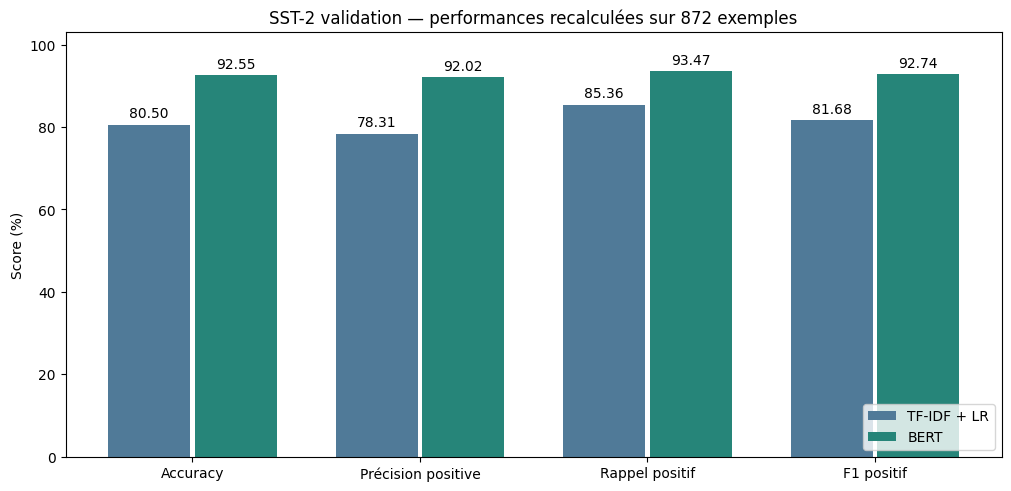

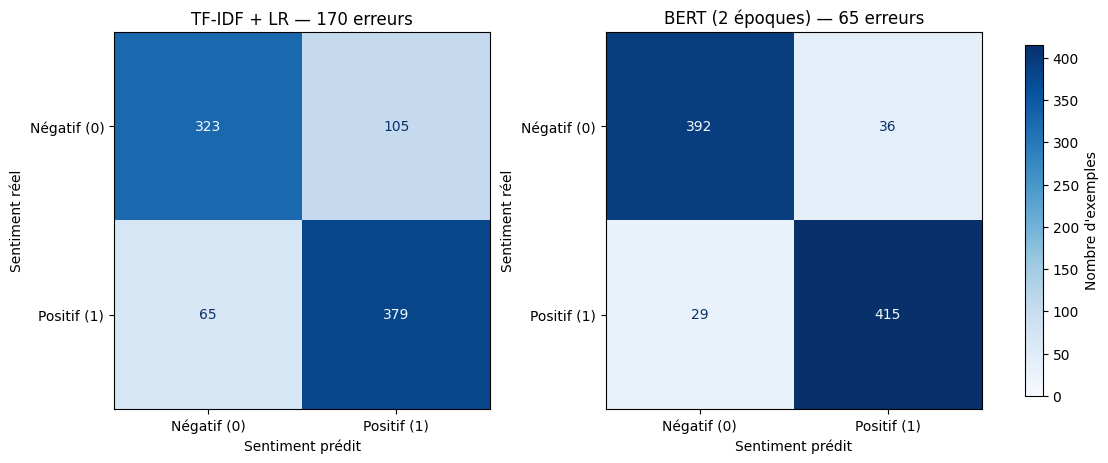

BERT gagne **12.04 points d'accuracy** et **11.06 points de F1 positif**. Il commet **105 erreurs de moins**, soit **61.76 %** de réduction relative. Les faux positifs passent de **105 à 36** et les faux négatifs de **65 à 29** : le gain concerne les deux classes. Cela décrit cette expérience, sans établir une supériorité universelle.

In [2]:
p4_comparison = pd.DataFrame([
    {"Mesure": label, "TF-IDF + LR (%)": p4_tfidf_metrics[key] * 100,
     "BERT (%)": p4_bert_metrics[key] * 100,
     "Écart BERT − TF-IDF (pp)": (p4_bert_metrics[key] - p4_tfidf_metrics[key]) * 100}
    for key, label in P4_METRIC_NAMES.items()
])
p4_error_reduction = (p4_tfidf_metrics["n_errors"] - p4_bert_metrics["n_errors"]) / p4_tfidf_metrics["n_errors"] * 100
display(p4_comparison.round(2))
display(pd.DataFrame({"Modèle": ["TF-IDF + LR", "BERT"],
                      "Correctes": [872 - m["n_errors"] for m in (p4_tfidf_metrics, p4_bert_metrics)],
                      "Erreurs": [m["n_errors"] for m in (p4_tfidf_metrics, p4_bert_metrics)]}))

fig_perf, ax = plt.subplots(figsize=(10, 4.8), layout="constrained")
x = np.arange(len(p4_comparison))
for shift, column, label, color in ((-0.19, "TF-IDF + LR (%)", "TF-IDF + LR", "#507A98"),
                                    (0.19, "BERT (%)", "BERT", "#268579")):
    bars = ax.bar(x + shift, p4_comparison[column], width=0.36, label=label, color=color)
    ax.bar_label(bars, labels=[f"{value:.2f}" for value in p4_comparison[column]], padding=3, fontsize=10)
ax.set(xticks=x, xticklabels=p4_comparison["Mesure"], ylim=(0, 103), ylabel="Score (%)",
       title="SST-2 validation — performances recalculées sur 872 exemples")
ax.legend(loc="lower right")
plt.show()

fig_cm, axes = plt.subplots(1, 2, figsize=(11, 4.6), layout="constrained")
vmax = max(np.max(p4_tfidf_metrics["confusion_matrix"]), np.max(p4_bert_metrics["confusion_matrix"]))
for ax, name, metrics in zip(axes, ["TF-IDF + LR", "BERT (2 époques)"], [p4_tfidf_metrics, p4_bert_metrics]):
    cm_display = ConfusionMatrixDisplay(np.asarray(metrics["confusion_matrix"]), display_labels=["Négatif (0)", "Positif (1)"])
    cm_display.plot(ax=ax, cmap="Blues", values_format="d", colorbar=False, im_kw={"vmin": 0, "vmax": vmax})
    ax.set(title=f"{name} — {metrics['n_errors']} erreurs", xlabel="Sentiment prédit", ylabel="Sentiment réel")
fig_cm.colorbar(cm_display.im_, ax=axes, shrink=0.85, label="Nombre d'exemples")
plt.show()

display(Markdown(
    f"BERT gagne **{(p4_bert_metrics['accuracy']-p4_tfidf_metrics['accuracy'])*100:.2f} points d'accuracy** "
    f"et **{(p4_bert_metrics['f1']-p4_tfidf_metrics['f1'])*100:.2f} points de F1 positif**. "
    f"Il commet **105 erreurs de moins**, soit **{p4_error_reduction:.2f} %** de réduction relative. "
    "Les faux positifs passent de **105 à 36** et les faux négatifs de **65 à 29** : "
    "le gain concerne les deux classes. Cela décrit cette expérience, sans établir une supériorité universelle."
))


### 5.2 — Succès et erreurs appariés ; test exact de McNemar

Pour chaque `idx`, nous comparons les indicateurs « prédiction correcte ».
Les deux modèles partagent les mêmes labels : les quatre groupes ci-dessous
partitionnent les 872 exemples. Dans cette tâche binaire, deux prédictions
différentes impliquent qu'un seul modèle a raison.

Le test exact de McNemar porte sur les deux groupes discordants. Sous l'hypothèse
nulle de symétrie des erreurs, leurs directions ont probabilité 1/2 ; on applique
un test binomial exact bilatéral. Il teste les taux d'erreur appariés, **pas
directement la différence de F1**, ni une cause interne du gain. L'interprétation
suppose des observations indépendantes entre phrases ; des dépendances entre
critiques ou films ne sont pas contrôlées faute de groupes disponibles. Une seule
seed et une seule validation ne mesurent pas la variabilité entre entraînements.


,Situation,Exemples,Part (%)
0,Les deux réussissent,671,76.95
1,Les deux échouent,34,3.90
2,BERT seul réussit,136,15.60
3,TF-IDF seul réussit,31,3.56


,BERT correct,BERT incorrect
TF-IDF correct,671,31
TF-IDF incorrect,136,34


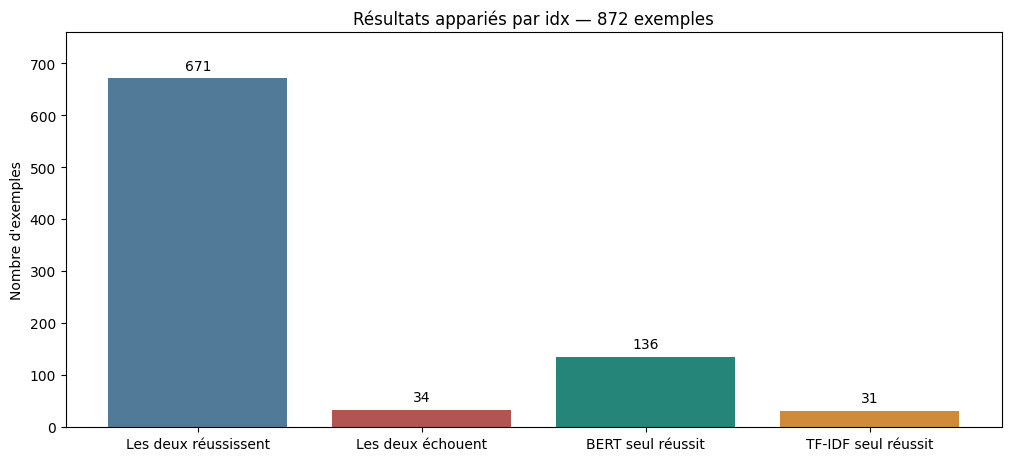

BERT corrige **136 des 170 erreurs TF-IDF (80 %)**, mais se trompe sur **31 exemples que TF-IDF réussit**. Les 34 erreurs communes restent difficiles pour les deux approches ; la complémentarité existe, sans qu'un système combiné ait été évalué. Sur les **167 désaccords**, McNemar exact donne **p = 6.883e-17**. Cette petite p-valeur indique une asymétrie marquée sur cette validation, sans démontrer une généralisation universelle ni l'effet causal du préentraînement.

In [3]:
def p4_paired_analysis(aligned):
    tf_correct = aligned["true_label_tfidf"].eq(aligned["predicted_label_tfidf"])
    bert_correct = aligned["true_label_bert"].eq(aligned["predicted_label_bert"])
    counts = {"both_correct": int((tf_correct & bert_correct).sum()),
              "both_wrong": int((~tf_correct & ~bert_correct).sum()),
              "bert_only_correct": int((~tf_correct & bert_correct).sum()),
              "tfidf_only_correct": int((tf_correct & ~bert_correct).sum())}
    assert sum(counts.values()) == len(aligned)
    n = counts["bert_only_correct"] + counts["tfidf_only_correct"]
    k = min(counts["bert_only_correct"], counts["tfidf_only_correct"])
    pvalue = float(binomtest(k, n=n, p=0.5, alternative="two-sided").pvalue) if n else 1.0
    # Vérification indépendante de la somme binomiale pour p=1/2.
    exact_sum = min(1.0, 2 * sum(math.comb(n, i) for i in range(k + 1)) / 2**n) if n else 1.0
    assert math.isclose(pvalue, exact_sum, rel_tol=1e-12, abs_tol=1e-30)
    return counts, pvalue


p4_counts, p4_mcnemar_p = p4_paired_analysis(p4_aligned)
assert p4_counts == {"both_correct": 671, "both_wrong": 34, "bert_only_correct": 136, "tfidf_only_correct": 31}
assert p4_counts["bert_only_correct"] - p4_counts["tfidf_only_correct"] == p4_tfidf_metrics["n_errors"] - p4_bert_metrics["n_errors"]
p4_outcome_labels = {"both_correct": "Les deux réussissent", "both_wrong": "Les deux échouent",
                      "bert_only_correct": "BERT seul réussit", "tfidf_only_correct": "TF-IDF seul réussit"}
p4_outcomes = pd.DataFrame([{"Situation": p4_outcome_labels[key], "Exemples": count, "Part (%)": count / 872 * 100}
                            for key, count in p4_counts.items()])
display(p4_outcomes.round(2))
p4_paired_table = pd.DataFrame([
    [p4_counts["both_correct"], p4_counts["tfidf_only_correct"]],
    [p4_counts["bert_only_correct"], p4_counts["both_wrong"]]],
    index=["TF-IDF correct", "TF-IDF incorrect"], columns=["BERT correct", "BERT incorrect"])
display(p4_paired_table)
fig_paired, ax = plt.subplots(figsize=(10, 4.5), layout="constrained")
bars = ax.bar(p4_outcomes["Situation"], p4_outcomes["Exemples"],
              color=["#507A98", "#B25550", "#268579", "#CF8B39"])
ax.bar_label(bars, padding=4)
ax.set(title="Résultats appariés par idx — 872 exemples", ylabel="Nombre d'exemples", ylim=(0, 760))
plt.show()
display(Markdown(
    f"BERT corrige **{p4_counts['bert_only_correct']} des 170 erreurs TF-IDF (80 %)**, "
    f"mais se trompe sur **{p4_counts['tfidf_only_correct']} exemples que TF-IDF réussit**. "
    "Les 34 erreurs communes restent difficiles pour les deux approches ; la complémentarité existe, "
    "sans qu'un système combiné ait été évalué. "
    f"Sur les **167 désaccords**, McNemar exact donne **p = {p4_mcnemar_p:.3e}**. "
    "Cette petite p-valeur indique une asymétrie marquée sur cette validation, "
    "sans démontrer une généralisation universelle ni l'effet causal du préentraînement."
))


### 5.3 — Dix erreurs réelles de BERT : hypothèses linguistiques

Les dix `idx` proposés sont tous vérifiés dans les 65 erreurs réelles. Cinq sont
réussis par TF-IDF et cinq sont des erreurs communes. Le choix est **illustratif,
non aléatoire** : il ne permet pas d'estimer la fréquence des causes d'erreur.
Les catégories décrivent des indices visibles ; elles ne disent pas quels tokens,
poids ou têtes d'attention ont produit la décision. Les labels SST-2 sont conservés,
même lorsqu'une phrase isolée reste ambiguë. L'ironie est mentionnée comme lecture
possible uniquement lorsque la formulation s'y prête, jamais comme fait établi.


In [4]:
P4_ERROR_NOTES = {
    205: ("Éloge familier / opinion mixte", "good stupid fun",
          "« good stupid fun » peut exprimer un plaisir assumé malgré l'adjectif péjoratif « stupid ». Une difficulté de composition du jugement est plausible, sans indice sur le mécanisme interne."),
    411: ("Négations et opposition", "do n't treat me like a fool",
          "La concession initiale (« I don't mind ») est suivie d'un reproche introduit par « but ». La portée respective de la concession et du reproche est une difficulté possible."),
    580: ("Comparaison défavorable / sarcasme possible", "worse than expected",
          "« worse than expected » reste négatif malgré la tournure « manages to do exactly that ». Cette réussite formulée comme un échec peut se lire comme sarcastique ; cette lecture n'est pas démontrée."),
    724: ("Négation idiomatique", "do n't go to the movies for",
          "La négation renverse une formule qui pourrait sinon être élogieuse : le film représente ce que l'on ne recherche pas au cinéma. L'interprétation globale de l'idiome est une piste."),
    770: ("Absence d'une réaction positive", "do n't think i laughed",
          "Le locuteur ne rapporte aucun éclat de rire. La négation et « once » orientent ici vers une appréciation négative, sans prouver quel indice BERT a manqué."),
    93: ("Valorisation concessive", "glorious failure",
         "« glorious failure » associe un échec à une valorisation paradoxale. Le label positif retient cette valorisation ; l'extrait peut conserver une ambivalence sans contexte supplémentaire."),
    112: ("Ambiguïté lexicale / humour", "hilariously inept",
          "« hilariously » peut valoriser le plaisir comique, tandis que « inept and ridiculous » peut aussi être une critique. Le label positif est celui du corpus ; ni l'ironie ni une annotation erronée ne sont établies."),
    172: ("Idiome enthousiaste sous négation", "ca n't wait for the sequel",
          "« can't wait for the sequel » exprime une impatience positive malgré sa forme négative. Une lecture trop littérale serait une hypothèse, pas une observation du calcul de BERT."),
    183: ("Éloge conditionnel / ironie possible", "the lower your expectations",
          "Le plaisir est conditionné à de faibles attentes, ce qui peut constituer un jugement défavorable. Une lecture ironique est possible, mais la phrase seule ne la démontre pas."),
    728: ("Négation d'un jugement négatif / litote", "can not be said to suck",
          "« cannot be said to suck » atténue ou inverse la critique, avec « stylish and energetic » comme appréciation positive. La négation indirecte est une difficulté plausible, sans causalité démontrée."),
}
p4_error_rows = []
for idx, (category, evidence, hypothesis) in P4_ERROR_NOTES.items():
    row = p4_aligned.set_index("idx").loc[idx]
    assert row["true_label_bert"] != row["predicted_label_bert"]
    assert evidence in row["sentence_bert"]
    confidence = row["probability_positive"] if row["predicted_label_bert"] == 1 else 1 - row["probability_positive"]
    p4_error_rows.append({"idx": idx, "Phrase": row["sentence_bert"], "Réel": int(row["true_label_bert"]),
                          "BERT": int(row["predicted_label_bert"]), "TF-IDF": int(row["predicted_label_tfidf"]),
                          "Confiance BERT (%)": float(confidence * 100),
                          "Catégorie hypothétique": category, "Hypothèse explicative": hypothesis})
p4_error_analysis = pd.DataFrame(p4_error_rows)
assert len(p4_error_analysis) == 10 and p4_error_analysis["idx"].is_unique
with pd.option_context("display.max_colwidth", None, "display.max_columns", None):
    display(p4_error_analysis.round({"Confiance BERT (%)": 2}))
print("0 = négatif ; 1 = positif. Confiance = probabilité attribuée à la classe prédite, pas probabilité d'avoir raison.")


,idx,Phrase,Réel,BERT,TF-IDF,Confiance BERT (%),Catégorie hypothétique,Hypothèse explicative
0,205,falls neatly into the category of good stupid fun .,1,0,1,85.23,Éloge familier / opinion mixte,"« good stupid fun » peut exprimer un plaisir assumé malgré l'adjectif péjoratif « stupid ». Une difficulté de composition du jugement est plausible, sans indice sur le mécanisme interne."
1,411,"i do n't mind having my heartstrings pulled , but do n't treat me like a fool .",0,1,0,98.07,Négations et opposition,La concession initiale (« I don't mind ») est suivie d'un reproche introduit par « but ». La portée respective de la concession et du reproche est une difficulté possible.
2,580,"it takes a certain kind of horror movie to qualify as ` worse than expected , ' but ghost ship somehow manages to do exactly that .",0,1,0,98.39,Comparaison défavorable / sarcasme possible,« worse than expected » reste négatif malgré la tournure « manages to do exactly that ». Cette réussite formulée comme un échec peut se lire comme sarcastique ; cette lecture n'est pas démontrée.
3,724,it 's everything you do n't go to the movies for .,0,1,0,99.96,Négation idiomatique,La négation renverse une formule qui pourrait sinon être élogieuse : le film représente ce que l'on ne recherche pas au cinéma. L'interprétation globale de l'idiome est une piste.
4,770,i do n't think i laughed out loud once .,0,1,0,70.74,Absence d'une réaction positive,"Le locuteur ne rapporte aucun éclat de rire. La négation et « once » orientent ici vers une appréciation négative, sans prouver quel indice BERT a manqué."
5,93,if steven soderbergh 's ` solaris ' is a failure it is a glorious failure .,1,0,0,85.33,Valorisation concessive,« glorious failure » associe un échec à une valorisation paradoxale. Le label positif retient cette valorisation ; l'extrait peut conserver une ambivalence sans contexte supplémentaire.
6,112,hilariously inept and ridiculous .,1,0,0,99.73,Ambiguïté lexicale / humour,"« hilariously » peut valoriser le plaisir comique, tandis que « inept and ridiculous » peut aussi être une critique. Le label positif est celui du corpus ; ni l'ironie ni une annotation erronée ne sont établies."
7,172,it seems like i have been waiting my whole life for this movie and now i ca n't wait for the sequel .,1,0,0,58.36,Idiome enthousiaste sous négation,"« can't wait for the sequel » exprime une impatience positive malgré sa forme négative. Une lecture trop littérale serait une hypothèse, pas une observation du calcul de BERT."
8,183,"the lower your expectations , the more you 'll enjoy it .",0,1,1,99.95,Éloge conditionnel / ironie possible,"Le plaisir est conditionné à de faibles attentes, ce qui peut constituer un jugement défavorable. Une lecture ironique est possible, mais la phrase seule ne la démontre pas."
9,728,"but taken as a stylish and energetic one-shot , the queen of the damned can not be said to suck .",1,0,0,78.21,Négation d'un jugement négatif / litote,"« cannot be said to suck » atténue ou inverse la critique, avec « stylish and energetic » comme appréciation positive. La négation indirecte est une difficulté plausible, sans causalité démontrée."


0 = négatif ; 1 = positif. Confiance = probabilité attribuée à la classe prédite, pas probabilité d'avoir raison.


### 5.4 — Analyse du risque de surapprentissage et de la confiance prédictive

La loss train du tableau est **la dernière fenêtre journalisée avant chaque
validation**, aux étapes 4 200 et 8 400 ; ce n'est pas une moyenne par époque.
La validation intervient aux étapes 4 210 et 8 420. Les courbes conservent les
mesures réelles sans interpolation de nouveaux scores.

L'accuracy ne dépend que de la classe choisie ; la log-loss pénalise
`−log(probabilité de la vraie classe)`. Quelques erreurs très confiantes peuvent
donc augmenter la loss malgré davantage de décisions correctes. C'est une
explication mathématiquement possible, pas une attribution établie de la hausse
observée : les probabilités individuelles de l'époque 1 ne sont pas disponibles.
Deux validations ne démontrent pas à elles seules un surapprentissage.

Les dernières fenêtres de training loss passent de **0,160300 à 0,096000**, alors que la validation loss augmente de **0,253271 à 0,291790**. L'accuracy progresse simultanément de **91,8578 % à 92,5459 %**, et le F1 positif de **92,0670 % à 92,7374 %**. Cette divergence est un signal à surveiller, sans constituer à elle seule une preuve de surapprentissage.

Parmi les 65 erreurs finales, **48** ont au moins 90 % de confiance et **20** dépassent 99 %. Ces décisions erronées et confiantes ne suffisent pas à caractériser globalement la calibration : aucune courbe de fiabilité, ECE ou score de Brier n'a été calculé. Sans probabilités individuelles de l'époque 1, une dégradation de calibration entre les deux époques ne peut pas être affirmée.


,Époque,Étape validation,Dernière loss train (fenêtre),Étape loss train,Validation loss,Accuracy (%),F1 positif (%)
0,1,4210,0.1603,4200,0.253271,91.857798,92.067039
1,2,8420,0.0960,8400,0.291790,92.545872,92.737430


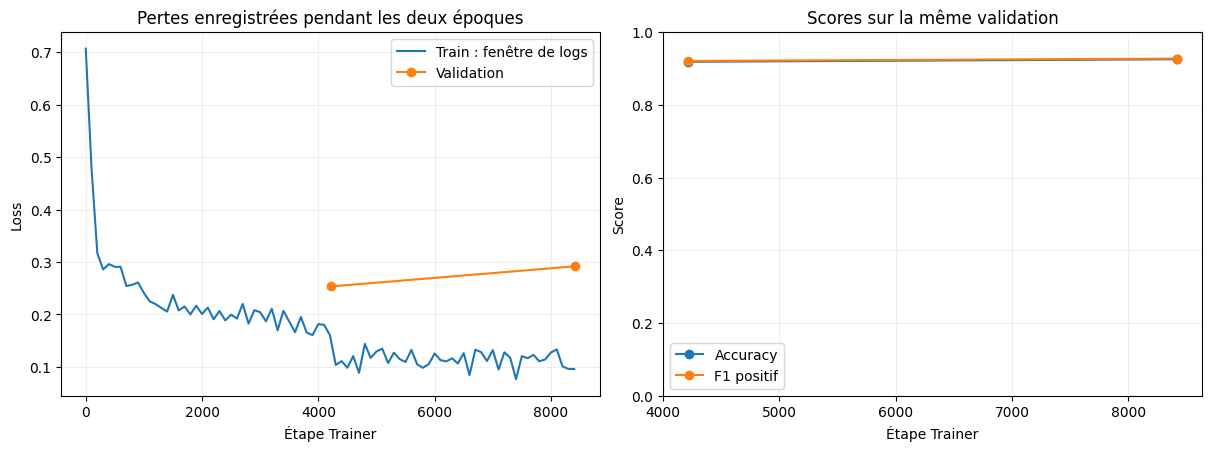

,idx,true_label,predicted_label,probability_positive,confidence,nll
544,544,0,1,0.999815,0.999815,8.597841
519,519,0,1,0.999661,0.999661,7.988621
724,724,0,1,0.999607,0.999607,7.842190
183,183,0,1,0.999549,0.999549,7.703576
95,95,0,1,0.999459,0.999459,7.522026


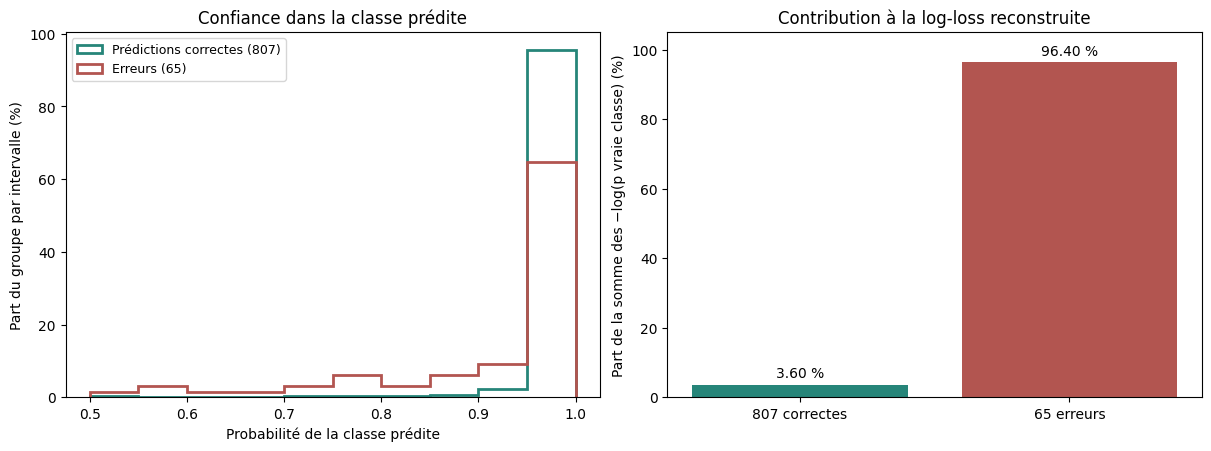

**Faits mesurés :** la validation loss passe de **0.253271** à **0.291790**, alors que l'accuracy gagne **0.69 point**. Parmi les 65 erreurs finales, **48** ont au moins 90 % de confiance et **20** plus de 99 %. Elles représentent **96.40 %** de la log-loss reconstruite ; cela n'est pas une étude complète de calibration. La moyenne reconstruite depuis les logits vaut **0.291784328**, contre **0.291790426** enregistrée par Trainer (écart absolu **6.10e-06**). Ce petit écart est compatible avec des différences numériques de précision/agrégation ; leur contribution exacte n'a pas été isolée. Aucun fichier validé n'est corrigé.

In [5]:
def p4_epoch_summary(history):
    metrics = ["eval_loss", "eval_accuracy", "eval_f1_positive"]
    selected = history.loc[history["metric"].isin(metrics)]
    if selected.duplicated(["epoch", "metric"]).any():
        raise ValueError("Plusieurs mesures de validation pour une même époque/métrique.")
    pivot = selected.pivot(index=["step", "epoch"], columns="metric", values="value").reset_index()
    if list(pivot["epoch"]) != [1.0, 2.0] or pivot.isna().any().any():
        raise ValueError("Deux validations complètes, une par époque, sont requises.")
    rows = []
    previous_step = 0
    for row in pivot.itertuples():
        train = history.loc[history["metric"].eq("loss") & history["step"].gt(previous_step) & history["step"].le(row.step)].sort_values("step")
        if train.empty:
            raise ValueError("Fenêtre de loss train manquante avant la validation.")
        last = train.iloc[-1]
        rows.append({"Époque": int(row.epoch), "Étape validation": int(row.step),
                     "Dernière loss train (fenêtre)": float(last["value"]), "Étape loss train": int(last["step"]),
                     "Validation loss": float(row.eval_loss), "Accuracy (%)": float(row.eval_accuracy * 100),
                     "F1 positif (%)": float(row.eval_f1_positive * 100)})
        previous_step = row.step
    return pd.DataFrame(rows)


p4_epochs = p4_epoch_summary(p4_history)
assert math.isclose(p4_epochs.iloc[-1]["Validation loss"], p4_bert_json["validation_loss"], abs_tol=1e-12)
assert math.isclose(p4_epochs.iloc[-1]["Accuracy (%)"] / 100, p4_bert_metrics["accuracy"], abs_tol=1e-12)
assert math.isclose(p4_epochs.iloc[-1]["F1 positif (%)"] / 100, p4_bert_metrics["f1"], abs_tol=1e-12)
display(p4_epochs.round(6))

fig_training, axes = plt.subplots(1, 2, figsize=(12, 4.4), layout="constrained")
for metric, label in (("loss", "Train : fenêtre de logs"), ("eval_loss", "Validation")):
    rows = p4_history.loc[p4_history["metric"].eq(metric)].sort_values("step")
    axes[0].plot(rows["step"], rows["value"], label=label, marker="o" if metric == "eval_loss" else None)
for metric, label in (("eval_accuracy", "Accuracy"), ("eval_f1_positive", "F1 positif")):
    rows = p4_history.loc[p4_history["metric"].eq(metric)].sort_values("step")
    axes[1].plot(rows["step"], rows["value"], marker="o", label=label)
axes[0].set(title="Pertes enregistrées pendant les deux époques", xlabel="Étape Trainer", ylabel="Loss")
axes[1].set(title="Scores sur la même validation", xlabel="Étape Trainer", ylabel="Score", ylim=(0, 1))
for ax in axes:
    ax.legend()
    ax.grid(alpha=0.2)
plt.show()

p4_wrong = p4_bert["true_label"].ne(p4_bert["predicted_label"])
p4_confidence = np.maximum(p4_probability, 1 - p4_probability)
p4_nll = p4_logits.max(axis=1) + np.log(np.exp(p4_shifted).sum(axis=1)) - p4_logits[np.arange(872), p4_bert["true_label"].to_numpy()]
p4_reconstructed_loss = float(p4_nll.mean())
p4_loss_gap = abs(p4_reconstructed_loss - p4_bert_json["validation_loss"])
assert p4_loss_gap < 1e-4, "Écart de loss à investiguer avant publication."
p4_confident_errors_90 = int((p4_confidence[p4_wrong] >= 0.90).sum())
p4_confident_errors_99 = int((p4_confidence[p4_wrong] > 0.99).sum())
assert (p4_confident_errors_90, p4_confident_errors_99) == (48, 20)
p4_error_loss_share = float(p4_nll[p4_wrong].sum() / p4_nll.sum() * 100)
p4_confident_examples = p4_bert.assign(confidence=p4_confidence, nll=p4_nll).loc[p4_wrong].sort_values("confidence", ascending=False).head(5)
display(p4_confident_examples[["idx", "true_label", "predicted_label", "probability_positive", "confidence", "nll"]].round(6))

fig_confidence, axes = plt.subplots(1, 2, figsize=(12, 4.4), layout="constrained")
bins = np.linspace(0.5, 1.0, 11)
for mask, label, color in ((~p4_wrong, "Prédictions correctes (807)", "#268579"), (p4_wrong, "Erreurs (65)", "#B25550")):
    values = p4_confidence[mask]
    axes[0].hist(values, bins=bins, weights=np.full(len(values), 100 / len(values)),
                 histtype="step", linewidth=2, label=label, color=color)
axes[0].set(title="Confiance dans la classe prédite", xlabel="Probabilité de la classe prédite", ylabel="Part du groupe par intervalle (%)")
axes[0].legend(fontsize=9)
shares = [100 - p4_error_loss_share, p4_error_loss_share]
bars = axes[1].bar(["807 correctes", "65 erreurs"], shares, color=["#268579", "#B25550"])
axes[1].bar_label(bars, labels=[f"{value:.2f} %" for value in shares], padding=3)
axes[1].set(title="Contribution à la log-loss reconstruite", ylabel="Part de la somme des −log(p vraie classe) (%)", ylim=(0, 105))
plt.show()

display(Markdown(
    f"**Faits mesurés :** la validation loss passe de **{p4_epochs.iloc[0]['Validation loss']:.6f}** "
    f"à **{p4_epochs.iloc[1]['Validation loss']:.6f}**, alors que l'accuracy gagne "
    f"**{p4_epochs.iloc[1]['Accuracy (%)'] - p4_epochs.iloc[0]['Accuracy (%)']:.2f} point**. "
    f"Parmi les 65 erreurs finales, **{p4_confident_errors_90}** ont au moins 90 % de confiance "
    f"et **{p4_confident_errors_99}** plus de 99 %. Elles représentent **{p4_error_loss_share:.2f} %** "
    "de la log-loss reconstruite ; cela n'est pas une étude complète de calibration. "
    f"La moyenne reconstruite depuis les logits vaut **{p4_reconstructed_loss:.9f}**, contre "
    f"**{p4_bert_json['validation_loss']:.9f}** enregistrée par Trainer (écart absolu **{p4_loss_gap:.2e}**). "
    "Ce petit écart est compatible avec des différences numériques de précision/agrégation ; "
    "leur contribution exacte n'a pas été isolée. Aucun fichier validé n'est corrigé."
))


### 5.5 — Conclusion scientifique (sept lignes)

Sur SST-2, TF-IDF + régression logistique constitue une référence lexicale solide, avec 80,50 % d'accuracy.  
BERT atteint 92,55 % d'accuracy et 92,74 % de F1 positif après deux époques de fine-tuning supervisé.  
Le préentraînement MLM fournit un point de départ linguistique dont l'encodeur produit des représentations contextuelles.  
La représentation de `[CLS]`, passée par le pooler et la tête binaire, est adaptée avec l'encodeur aux labels SST-2.  
Le gain net de 105 bonnes décisions combine 136 corrections et 31 nouvelles erreurs par rapport à la baseline.  
Les erreurs ambiguës et confiantes, ainsi que la hausse de validation loss, invitent à distinguer correction et qualité probabiliste.  
Ce seul run sur une validation ne démontre ni l'effet causal d'un mécanisme interne ni une généralisation à d'autres domaines.

Les nombres ci-dessus sont contrôlés par les calculs des cellules précédentes.
Le rapport suivant distingue les faits mesurés, les hypothèses qualitatives et
les limites : une seule seed, un seul split, dix erreurs choisies, probabilités
d'époque 1 indisponibles, comparaison de systèmes sans ablation du préentraînement.


### 5.6 — Rapport final et contrôles de préservation

La cellule suivante écrit `report/summary.md` et cinq figures issues des calculs
ci-dessus. Elle ne remplace aucun JSON, CSV ou PNG validé dans `results/` et ne
modifie pas l'audit préexistant. Les empreintes des sources sont contrôlées après
génération. Aucun commit ni push n'est exécuté.


In [6]:
def p4_markdown_table(headers, rows):
    def escape(value):
        return str(value).replace("|", chr(92) + "|").replace("`", chr(92) + "`").replace(chr(10), " ")
    return chr(10).join([
        "| " + " | ".join(map(escape, headers)) + " |",
        "| " + " | ".join("---" for _ in headers) + " |",
        *("| " + " | ".join(map(escape, row)) + " |" for row in rows),
    ])


def p4_french(value, digits=2):
    return f"{value:.{digits}f}".replace(".", ",")


def p4_summary_text():
    quantitative = p4_markdown_table(
        ["Mesure", "TF-IDF + LR", "BERT", "Écart BERT − TF-IDF (pp)"],
        [(row["Mesure"], p4_french(row["TF-IDF + LR (%)"]) + " %", p4_french(row["BERT (%)"]) + " %",
          "+" + p4_french(row["Écart BERT − TF-IDF (pp)"])) for row in p4_comparison.to_dict("records")])
    counts_table = p4_markdown_table(["Situation appariée", "Exemples", "Part de la validation"],
        [(row["Situation"], row["Exemples"], p4_french(row["Part (%)"]) + " %") for row in p4_outcomes.to_dict("records")])
    error_table = p4_markdown_table(["idx", "Phrase originale", "Réel", "BERT", "TF-IDF", "Confiance BERT", "Hypothèse linguistique"],
        [(row["idx"], row["Phrase"], row["Réel"], row["BERT"], row["TF-IDF"], p4_french(row["Confiance BERT (%)"]) + " %",
          row["Catégorie hypothétique"] + " — " + row["Hypothèse explicative"])
         for row in p4_error_analysis.to_dict("records")])
    epoch_table = p4_markdown_table(
        ["Époque", "Étape validation", "Dernière loss train (fenêtre)", "Étape de cette fenêtre", "Validation loss", "Accuracy", "F1 positif"],
        [(row["Époque"], row["Étape validation"], p4_french(row["Dernière loss train (fenêtre)"], 6), row["Étape loss train"],
          p4_french(row["Validation loss"], 6), p4_french(row["Accuracy (%)"], 4) + " %", p4_french(row["F1 positif (%)"], 4) + " %")
         for row in p4_epochs.to_dict("records")])
    confidence_table = p4_markdown_table(["idx", "Réel", "BERT", "Probabilité positive", "Confiance classe prédite", "−log(p vraie classe)"],
        [(int(row.idx), int(row.true_label), int(row.predicted_label), p4_french(row.probability_positive, 6),
          p4_french(row.confidence * 100, 4) + " %", p4_french(row.nll, 4)) for row in p4_confident_examples.itertuples()])
    tf, bert = p4_tfidf_metrics, p4_bert_metrics
    params = p4_bert_json["hyperparameters"]
    env = p4_bert_json["environment"]
    parts = [
        "# Comparaison scientifique finale — BERT vs TF-IDF sur SST-2",
        "> Rapport de phase 4 fondé exclusivement sur les prédictions et journaux réels. Aucun modèle n'a été réentraîné pour ce reporting. Les métriques du smoke test sont exclues.",
        "## 1. Objectif scientifique et dataset",
        "Comparer une représentation lexicale TF-IDF suivie d'une régression logistique à un encodeur BERT préentraîné puis adapté à la classification du sentiment. SST-2 (GLUE, configuration nyu-mll/glue/sst2) contient des critiques de films en anglais ; le train comprend aussi des fragments annotés. Le split officiel train comporte **67 349 exemples**, et la validation **872** : **428 négatifs (0)** et **444 positifs (1)**. Aucun label du test officiel n'est exploité.",
        "## 2. Protocole et configuration des modèles",
        "Le vocabulaire, les IDF et le classifieur TF-IDF sont ajustés uniquement sur le train. La référence est celle du commit **ecb4c82e3a36fd1c3d3d05b2efaad01e996feb5a**, conservée dans [tfidf_metrics.json](../results/tfidf_metrics.json) et [tfidf_predictions.csv](../results/tfidf_predictions.csv). Les éventuelles réexécutions de la baseline dans Colab ne remplacent pas cette référence.",
        "**TF-IDF + LR :** unigrammes/bigrammes, min_df=2, max_df=1, max_features=100 000 (74 055 caractéristiques apprises), TF logarithmique, IDF lissée, norme L2, minuscules et aucun stopword. Régression logistique : pénalité L2, C=1, lbfgs, max_iter=1000, tol=1e-4, class_weight=None, seed 42. Aucun réglage sur la validation dans cette baseline.",
        f"**BERT :** {p4_bert_json['model_name']}, révision {p4_bert_json['pretrained_revision']}, tête binaire réinitialisée après seed {params['seed']}, puis encodeur et tête fine-tunés sur le train. **{params['num_train_epochs']} époques**, learning rate **{params['learning_rate']}**, max_length={params['max_length']}, padding dynamique, batch train={params['per_device_train_batch_size']}, batch évaluation={params['per_device_eval_batch_size']}, accumulation={params['gradient_accumulation_steps']}. AdamW, weight decay nul, scheduler linéaire sans warm-up, clipping à 1. GPU **{env['gpu']}**, FP16={env['fp16']}. Le modèle de fin d'époque 2 est retenu sans sélection de la meilleure époque selon la validation ; **8 420 étapes** terminées, sans reprise de checkpoint dans cette exécution.",
        f"Versions de l'expérience BERT : Python {env['python']}, PyTorch {env['torch_runtime']}, Transformers {env['versions']['transformers']}, Accelerate {env['versions']['accelerate']}. La durée enregistrée est **{p4_french(p4_bert_json['training_seconds'], 2)} s** (environ 13 min 10 s), validations et sauvegardes comprises. Le temps TF-IDF de {p4_french(p4_tfidf_json['training_seconds'], 2)} s est mesuré sur CPU et ne couvre que l'apprentissage : ces durées ne constituent pas un benchmark matériel comparable.",
        "Le MLM préentraîne BERT à reconstruire des tokens masqués ; son encodeur produit des représentations contextuelles. Pour la classification, la représentation de [CLS] passe par le pooler et une tête binaire, entraînée avec l'encodeur. Cette description du modèle fournit un cadre théorique ; notre comparaison ne constitue pas une ablation de ces composants. [Devlin et al., 2019](https://aclanthology.org/N19-1423/).",
        "## 3. Comparaison quantitative recalculée",
        quantitative,
        f"TF-IDF : **{872 - tf['n_errors']} bonnes décisions**, **{tf['n_errors']} erreurs**. BERT : **{872 - bert['n_errors']} bonnes décisions**, **{bert['n_errors']} erreurs**. Gain net : **{tf['n_errors'] - bert['n_errors']} bonnes décisions** ; réduction relative des erreurs : **{p4_french(p4_error_reduction)} %**. Tous les écarts en points sont calculés avant arrondi ; soustraire les pourcentages déjà arrondis peut donner un dernier chiffre différent.",
        "![Comparaison des quatre métriques](figures/performance_comparison.png)",
        "## 4. Matrices de confusion",
        "Lignes = sentiments réels, colonnes = sentiments prédits ; ordre **[négatif (0), positif (1)]**. Même échelle de couleurs et effectifs bruts pour les deux graphiques.",
        f"TF-IDF : **{tf['confusion_matrix']}** ; BERT : **{bert['confusion_matrix']}**. Les faux positifs diminuent de 105 à 36 et les faux négatifs de 65 à 29. Précision et rappel positifs progressent tous les deux sur ce split.",
        "![Matrices de confusion côte à côte](figures/confusion_matrices.png)",
        "## 5. Prédictions appariées et McNemar exact",
        "Les fichiers sont fusionnés par **idx**, avec unicité, égalité des ensembles d'identifiants, des textes et des vrais labels. Les quatre groupes couvrent exactement les 872 exemples.",
        counts_table,
        "BERT réussit 136 des 170 erreurs de la baseline, soit **80 %**, mais échoue sur 31 cas que TF-IDF réussit. Les 136 corrections moins ces 31 régressions donnent le gain net de 105. Les 34 erreurs communes indiquent des difficultés partagées, sans permettre de conclure que leurs causes internes sont identiques. Aucun ensemble combinant les modèles n'a été évalué.",
        "![Quatre groupes de résultats appariés](figures/paired_outcomes.png)",
        f"**Test exact bilatéral de McNemar : p = {p4_mcnemar_p:.6e}.** Sous H0 de symétrie des erreurs, les **167 paires discordantes** ont des directions équiprobables : 136 favorisent BERT et 31 TF-IDF. Le calcul utilise un test binomial exact avec n=167, k=31 et p0=0,5, et a été vérifié par somme des probabilités binomiales. [API SciPy binomtest](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.binomtest.html).",
        "Cette asymétrie est statistiquement marquée pour ces modèles fixés et ces exemples appariés. Le test concerne leurs taux d'erreur, pas directement le F1 ; il ne mesure pas la variabilité entre seeds, ne prouve aucun mécanisme causal et suppose l'indépendance entre observations. Des phrases issues d'un même film ou d'une même critique pourraient être dépendantes ; aucun regroupement n'est disponible ici pour le contrôler.",
        "## 6. Dix erreurs réelles de BERT",
        "Les dix identifiants proposés sont tous des erreurs vérifiées dans le CSV final. Cinq sont réussis par TF-IDF et cinq sont des erreurs communes. Leur sélection est illustrative, non aléatoire : aucune fréquence générale de catégories ne doit en être déduite. **0 = négatif ; 1 = positif.** La confiance est la probabilité de la classe prédite, pas une probabilité que la décision soit correcte.",
        error_table,
        "Ces hypothèses décrivent des négations, concessions, idiomes, opinions mixtes ou ambiguïtés visibles. Elles ne sont pas des explications causales démontrées et ne reposent sur aucune inspection d'attention ou ablation. L'ironie reste une lecture possible dans les formulations concernées. Les labels surprenants, notamment pour « hilariously inept and ridiculous », sont conservés tels qu'annotés ; nous ne démontrons pas une erreur d'annotation.",
        "## 7. Analyse du risque de surapprentissage et de la confiance prédictive",
        epoch_table,
        "**Attention :** 0,160300 et 0,096000 sont les dernières fenêtres de loss train journalisées avant les validations, aux étapes 4 200 et 8 400. Les validations ont lieu à 4 210 et 8 420. Ces valeurs ne sont pas les moyennes d'apprentissage des époques. Le résumé final de Trainer donne une train_loss agrégée de 0,167511 ; elle décrit encore une autre mesure. La loss train avec dropout et fenêtres de lots ne se compare pas directement à une loss de validation évaluée sur tout le split.",
        "![Pertes et scores réellement enregistrés](figures/training_curves.png)",
        "**Faits mesurés :** les dernières fenêtres de training loss diminuent de 0,160300 à 0,096000, tandis que la validation loss augmente de 0,253271 à 0,291790. Simultanément, l'accuracy progresse de 91,8578 % à 92,5459 % (six bonnes décisions supplémentaires) et le F1 positif de 92,0670 % à 92,7374 %. Cette divergence constitue un signal à surveiller pour le risque de surapprentissage et l'évolution de la confiance ; deux époques ne suffisent pas à démontrer un surapprentissage.",
        "**Explication possible :** l'accuracy ne change qu'avec la classe argmax ; la log-loss utilise −log(probabilité de la vraie classe). Une mauvaise décision très confiante coûte davantage qu'une erreur hésitante. Une évolution des probabilités peut donc augmenter la loss tout en améliorant le nombre de décisions correctes. C'est une propriété de la mesure, pas une preuve de ce qui a changé entre ces deux époques. [Définition de la log-loss](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.log_loss.html).",
        f"**État final vérifié :** {p4_confident_errors_90} des 65 erreurs ont une confiance au moins égale à 90 %, et {p4_confident_errors_99} une confiance strictement supérieure à 99 %. Ces erreurs portent **{p4_french(p4_error_loss_share)} %** de la somme des log-loss reconstruites. Les idx 724 et 183 illustrent des décisions erronées à environ 99,96 % et 99,95 % de confiance. Ce constat ne constitue pas une étude complète de calibration.",
        confidence_table,
        "![Confiance finale et contribution à la log-loss](figures/confidence_distribution.png)",
        f"**Contrôle numérique :** la moyenne de −log(p vraie classe) reconstruite en float64 depuis les logits exportés est **{p4_reconstructed_loss:.9f}**, contre **{p4_bert_json['validation_loss']:.9f}** pour la loss enregistrée par Trainer ; écart absolu **{p4_loss_gap:.2e}**. Il est compatible avec des différences de précision numérique ou d'agrégation, sans que leur contribution exacte ait été isolée. Les métriques discrètes et matrices correspondent exactement. Aucun résultat validé n'est modifié pour effacer cet écart.",
        "**Limite :** les probabilités individuelles de l'époque 1 ne sont pas exportées. Nous ne pouvons donc pas attribuer empiriquement la hausse de loss à un changement précis de confiance sur les mêmes erreurs entre les époques.",
        "## 8. Limites de l'expérience",
        "- Un seul entraînement par approche et une seule seed : aucune estimation de variabilité entre entraînements.\n- Une validation unique de 872 exemples, observée à chaque époque, sans test final indépendant ni évaluation hors domaine.\n- Des systèmes différents par leur architecture, taille et données de préentraînement : le gain n'isole pas causalement le MLM, [CLS] ou une tête d'attention.\n- La troncature à 64 tokens peut retirer du contexte ; son effet n'a pas fait l'objet d'une ablation.\n- Dix erreurs choisies pour illustration, contexte parfois limité et annotations pouvant sembler ambiguës : pas de causalité ni de prévalence de catégories démontrée.\n- Probabilités d'époque 1 absentes, calibration non évaluée systématiquement, et indépendance entre phrases non garantie pour McNemar.\n- Les durées CPU/GPU et périmètres de chronométrage diffèrent ; aucun ratio de coût équitable n'est établi.",
        "## 9. Conclusion principale — sept lignes",
        "Sur SST-2, TF-IDF + régression logistique constitue une référence lexicale solide, avec 80,50 % d'accuracy.  \nBERT atteint 92,55 % d'accuracy et 92,74 % de F1 positif après deux époques de fine-tuning supervisé.  \nLe préentraînement MLM fournit un point de départ linguistique dont l'encodeur produit des représentations contextuelles.  \nLa représentation de [CLS], passée par le pooler et la tête binaire, est adaptée avec l'encodeur aux labels SST-2.  \nLe gain net de 105 bonnes décisions combine 136 corrections et 31 nouvelles erreurs par rapport à la baseline.  \nLes erreurs ambiguës et confiantes, ainsi que la hausse de validation loss, invitent à distinguer correction et qualité probabiliste.  \nCe seul run sur une validation ne démontre ni l'effet causal d'un mécanisme interne ni une généralisation à d'autres domaines.",
        "## 10. Sources et vérifications de reporting",
        "Sources primaires : [métriques TF-IDF](../results/tfidf_metrics.json), [prédictions TF-IDF](../results/tfidf_predictions.csv), [métriques BERT](../results/phase3/bert_metrics.json), [prédictions BERT](../results/phase3/bert_predictions.csv), [historique](../results/phase3/bert_training_history.csv), [erreurs](../results/phase3/bert_errors.csv). L'[audit préalable](audit_phase3_bert_tfidf.md) a guidé la revue, mais les chiffres ont été recalculés à partir des CSV et JSON.",
        "Les six fichiers BERT étaient fournis dans phase3_results.zip ; les copies décompressées sont identiques octet pour octet à cette archive, conservée intacte. Les métriques, matrices, effectifs, probabilités et erreurs sont contrôlés avant génération. La section 4 du notebook a été actualisée pour indiquer l'expérience complète effectuée. Seules les cellules de reporting de section 5 ont été exécutées dans cette phase ; aucune inférence ni aucun entraînement supplémentaire.",
    ]
    return (chr(10) * 2).join(parts) + chr(10)


if P4_WRITE_REPORT:
    P4_FIGURES.mkdir(parents=True, exist_ok=True)
    for figure, name in ((fig_perf, "performance_comparison.png"), (fig_cm, "confusion_matrices.png"),
                         (fig_paired, "paired_outcomes.png"), (fig_training, "training_curves.png"),
                         (fig_confidence, "confidence_distribution.png")):
        figure.savefig(P4_FIGURES / name, dpi=170, bbox_inches="tight", facecolor="white")
        plt.close(figure)
    (P4_REPORT / "summary.md").write_text(p4_summary_text(), encoding="utf-8")
    print("Rapport créé : report/summary.md ; cinq figures sous report/figures/.")
for relative, digest in p4_source_hashes.items():
    source = P4_ROOT / relative
    if source.exists():
        assert hashlib.sha256(source.read_bytes()).hexdigest() == digest, relative
print("Empreintes des résultats et de l'audit inchangées. Fin de phase 4 : attendre la validation, sans commit ni push.")


Rapport créé : report/summary.md ; cinq figures sous report/figures/.
Empreintes des résultats et de l'audit inchangées. Fin de phase 4 : attendre la validation, sans commit ni push.
